# 02 — Time-series analysis

Timestamp regularity, sampling intervals, regular daily timeline and temporal features, ACF / PACF / Ljung-Box / ADF / KPSS, drift, seasonality, lead-lag relationships (→ `results/Exploratory_temporal.csv`), temporal feature engineering and validation schemes (temporal / spatial / random CV).

Run `01_eda.ipynb` first: this notebook reads `data/processed/combined_clean.csv` and completes `results/Exploratory_Data.csv` at the end.


In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Paths (notebooks/ -> ../data/raw, ../data/processed, ../results, ../folds)
RAW_DIR = "../data/raw"
PROCESSED_DIR = "../data/processed"
RESULTS_DIR = "../results"
FOLDS_DIR = "../folds"

combined = pd.read_csv(f"{RAW_DIR}/combined_gee_pm25.csv")
combined_clean = pd.read_csv(f"{PROCESSED_DIR}/combined_clean.csv")


Check timestamp regularity

In [ ]:
# Create a separate copy for temporal analysis
temporal_data = combined_clean.copy()

# Convert timestamp columns to datetime format
temporal_data["date"] = pd.to_datetime(temporal_data["date"])
temporal_data["datetime_utc"] = pd.to_datetime(temporal_data["datetime_utc"])

# Check data types
print("TIMESTAMP DATA TYPES")
print(temporal_data[["date", "datetime_utc"]].dtypes)

# Display examples
print("\nTIMESTAMP EXAMPLES")
display(temporal_data[["date", "datetime_utc", "id", "sensor_name"]].head())

# Check date range
print("\nDATE RANGE")
print("Earliest date:", temporal_data["date"].min())
print("Latest date:", temporal_data["date"].max())

# Count unique dates
print("\nNUMBER OF UNIQUE DATES")
print(temporal_data["date"].nunique())

# Check whether date and datetime_utc contain the same date
same_date = temporal_data["date"].dt.date == temporal_data["datetime_utc"].dt.date

print("Records with matching dates:", same_date.sum())
print("Records with different dates:", (~same_date).sum())

# Check whether datetime_utc always occurs at midnight
midnight_records = (
    temporal_data["datetime_utc"].dt.time == pd.Timestamp("00:00:00").time()
)

print("\nRecords at midnight:", midnight_records.sum())
print("Records not at midnight:", (~midnight_records).sum())

# Store temporal information for each GEE location
station_temporal = []

for station_id, group in temporal_data.groupby("id"):

    # Sort dates and remove repeated dates for interval analysis
    dates = group["date"].drop_duplicates().sort_values()

    # Calculate the difference between consecutive dates
    intervals = dates.diff().dt.days.dropna()

    # Calculate missing calendar dates
    missing_dates = (intervals - 1).clip(lower=0).sum()

    station_temporal.append(
        {
            "id": station_id,
            "sensor_name": group["sensor_name"].iloc[0],
            "n_records": len(group),
            "first_date": dates.min(),
            "last_date": dates.max(),
            "median_interval_days": intervals.median(),
            "missing_dates": int(missing_dates),
            "gaps_count": (intervals > 1).sum(),
        }
    )

station_temporal = pd.DataFrame(station_temporal)

# Display the results
print("Number of GEE locations:", len(station_temporal))

print("Stations with missing dates:", (station_temporal["missing_dates"] > 0).sum())

print(
    "Total missing calendar dates across stations:",
    station_temporal["missing_dates"].sum(),
)

print("\nSUMMARY OF SAMPLING INTERVALS")
display(station_temporal["median_interval_days"].describe())

print("\nSTATIONS WITH THE MOST MISSING DATES")
display(station_temporal.sort_values(by="missing_dates", ascending=False).head(10))

# Check duplicate timestamps for each GEE location
duplicate_dates = temporal_data.duplicated(subset=["id", "date"], keep=False)

print("Records involved in duplicate station-date timestamps:", duplicate_dates.sum())

# Check duplicate UTC timestamps for each GEE location
duplicate_utc = temporal_data.duplicated(subset=["id", "datetime_utc"], keep=False)

print("Records involved in duplicate station-UTC timestamps:", duplicate_utc.sum())

# Compare locations before and after cleaning
original_ids = set(combined["id"].unique())
cleaned_ids = set(temporal_data["id"].unique())

removed_ids = original_ids - cleaned_ids

print("\nLocations in original dataset:", len(original_ids))
print("Locations in cleaned dataset:", len(cleaned_ids))
print("Locations no longer present:", len(removed_ids))

print("\nRemoved location IDs:", sorted(removed_ids))


# Examine the three locations removed after cleaning
removed_locations = combined[combined["id"].isin([73, 74, 76])]

location_check = (
    removed_locations.groupby("id")
    .agg(
        total_records=("pm25", "count"),
        valid_pm25=("pm25", lambda x: ((x > 0) & (x < 500)).sum()),
        invalid_low=("pm25", lambda x: (x <= 0).sum()),
        invalid_high=("pm25", lambda x: (x >= 500).sum()),
        station_name=("sensor_name", "first"),
    )
    .reset_index()
)

display(location_check)

TIMESTAMP DATA TYPES
date            datetime64[us]
datetime_utc    datetime64[us]
dtype: object

TIMESTAMP EXAMPLES


,date,datetime_utc,id,sensor_name
0,2016-11-25,2016-11-25,1,ONTINYENT
1,2016-11-25,2016-11-25,36,ALMASSORA-C. P. OCHANDO
2,2016-11-30,2016-11-30,35,ALCORA
3,2016-11-30,2016-11-30,37,BENICASSIM
4,2016-12-02,2016-12-02,1,ONTINYENT



DATE RANGE
Earliest date: 2016-11-25 00:00:00
Latest date: 2026-04-06 00:00:00

NUMBER OF UNIQUE DATES
2299
Records with matching dates: 40983
Records with different dates: 0

Records at midnight: 40983
Records not at midnight: 0
Number of GEE locations: 95
Stations with missing dates: 94
Total missing calendar dates across stations: 54557

SUMMARY OF SAMPLING INTERVALS


count    95.000000
mean      1.052632
std       0.337967
min       1.000000
25%       1.000000
50%       1.000000
75%       1.000000
max       4.000000
Name: median_interval_days, dtype: float64


STATIONS WITH THE MOST MISSING DATES


,id,sensor_name,n_records,first_date,last_date,median_interval_days,missing_dates,gaps_count
5,7,VALÈNCIA - MOLÍ DEL SOL,561,2016-12-02,2026-02-09,1.0,2796,161
1,1,ONTINYENT,447,2016-11-25,2025-09-04,1.0,2759,134
8,10,VILAMARXANT,346,2018-01-17,2025-09-24,1.0,2462,129
86,101,ALGAR DE PALÀNCIA,771,2016-12-02,2023-04-12,1.0,1552,299
34,37,BENICASSIM,770,2016-11-30,2022-12-04,1.0,1426,293
35,38,BURRIANA,757,2016-12-02,2022-11-04,1.0,1407,299
9,11,SAGUNT CEA,797,2016-12-02,2022-11-12,1.0,1375,287
87,102,ALBALAT DELS TARONGERS,798,2016-12-02,2022-11-06,1.0,1368,296
32,35,ALCORA,761,2016-11-30,2022-09-06,1.0,1346,272
33,36,ALMASSORA-C. P. OCHANDO,739,2016-11-25,2022-07-09,1.0,1314,258


Records involved in duplicate station-date timestamps: 0
Records involved in duplicate station-UTC timestamps: 0

Locations in original dataset: 98
Locations in cleaned dataset: 95
Locations no longer present: 3

Removed location IDs: [np.int64(73), np.int64(74), np.int64(76)]


,id,total_records,valid_pm25,invalid_low,invalid_high,station_name
0,73,1,0,1,0,064F
1,74,4,0,4,0,testcompnex
2,76,4,0,4,0,mimiz


Analyze sampling intervals

In [ ]:
# Store all intervals between consecutive observations
all_intervals = []

for station_id, group in temporal_data.groupby("id"):

    dates = group["date"].drop_duplicates().sort_values()

    intervals = dates.diff().dt.days.dropna()

    for interval in intervals:
        all_intervals.append({"id": station_id, "interval_days": interval})

interval_data = pd.DataFrame(all_intervals)

# Summarize sampling intervals
print("TOTAL CONSECUTIVE OBSERVATION INTERVALS:", len(interval_data))

print("\nINTERVAL DISTRIBUTION")
display(interval_data["interval_days"].value_counts().sort_index().head(15))

# Calculate daily and irregular intervals
daily_intervals = (interval_data["interval_days"] == 1).sum()
irregular_intervals = (interval_data["interval_days"] > 1).sum()

print("\nDAILY SAMPLING")
print("Consecutive-day intervals:", daily_intervals)
print("Percentage:", round(daily_intervals / len(interval_data) * 100, 2), "%")

print("\nIRREGULAR SAMPLING")
print("Intervals longer than one day:", irregular_intervals)
print("Percentage:", round(irregular_intervals / len(interval_data) * 100, 2), "%")

print("\nLONGEST INTERVAL:", interval_data["interval_days"].max(), "days")

TOTAL CONSECUTIVE OBSERVATION INTERVALS: 40888

INTERVAL DISTRIBUTION


interval_days
1.0     27259
2.0      6497
3.0      3005
4.0      1407
5.0       825
6.0       572
7.0       387
8.0       147
9.0        83
10.0       89
11.0       75
12.0       37
13.0       25
14.0       60
15.0       30
Name: count, dtype: int64


DAILY SAMPLING
Consecutive-day intervals: 27259
Percentage: 66.67 %

IRREGULAR SAMPLING
Intervals longer than one day: 13629
Percentage: 33.33 %

LONGEST INTERVAL: 2383.0 days


## Regular daily timeline and temporal features

In [ ]:


# ------------------------------------------------------------
# 0. CONFIGURATION
# ------------------------------------------------------------

# Choose the forecasting scenario:
# "forecast"   = predict PM2.5 at least one day ahead
# "nowcasting" = predict PM2.5 for the same day

FORECAST_MODE = "forecast"

# Station retention criteria
# These are initial criteria that can be adjusted after
# examining the station coverage results.

MIN_COVERAGE = 0.30
MIN_VALID_DAYS = 365

# Approximately 0.25 degrees for coordinate matching checks
COORD_TOLERANCE = 0.25

# Work on a copy
data = combined_clean.copy()

# ------------------------------------------------------------
# 1. VALIDATE TIMESTAMPS AND IDENTIFIERS
# ------------------------------------------------------------

data["date"] = pd.to_datetime(data["date"]).dt.normalize()

print("DATASET VALIDATION")
print("------------------")

print("Total observations:", len(data))
print("Number of GEE IDs:", data["id"].nunique())
print("Number of sensor names:", data["sensor_name"].nunique())

print("\nMissing dates:")
print(data["date"].isna().sum())

print("\nMissing GEE IDs:")
print(data["id"].isna().sum())

print("\nDuplicate (ID, date) records:")
print(data.duplicated(subset=["id", "date"]).sum())

# Stop if duplicate station-date records exist
if data.duplicated(subset=["id", "date"]).any():
    raise ValueError(
        "Duplicate (id, date) records found. "
        "Resolve them before temporal preprocessing."
    )

if data["date"].isna().any() or data["id"].isna().any():
    raise ValueError("Missing date or GEE ID found.")

# ------------------------------------------------------------
# 2. VALIDATE EXISTING STATION-TO-GEE MATCHING
# ------------------------------------------------------------

print("\nEXISTING GEE MATCHING VALIDATION")
print("--------------------------------")

# Check missing coordinates
print("Missing latitude:", data["latitude"].isna().sum())
print("Missing longitude:", data["longitude"].isna().sum())

# Check how many coordinate pairs each GEE ID has
coordinates_per_id = (
    data.groupby("id")[["latitude", "longitude"]]
    .apply(lambda x: len(x.drop_duplicates()))
)

print("\nGEE IDs with more than one coordinate pair:")
print((coordinates_per_id > 1).sum())

# Check sensor names associated with each GEE ID
names_per_id = data.groupby("id")["sensor_name"].nunique()

print("\nGEE IDs associated with multiple sensor names:")
print((names_per_id > 1).sum())

# Check whether different GEE IDs share coordinates
coordinate_mapping = (
    data[["id", "latitude", "longitude"]]
    .drop_duplicates()
)

ids_per_coordinate = (
    coordinate_mapping.groupby(["latitude", "longitude"])["id"]
    .nunique()
)

print("\nCoordinate pairs associated with multiple GEE IDs:")
print((ids_per_coordinate > 1).sum())

# ------------------------------------------------------------
# 3. CREATE A REGULAR DAILY TIMELINE PER STATION
# ------------------------------------------------------------

regular_stations = []

for station_id, group in data.groupby("id"):

    group = group.sort_values("date").copy()

    # Complete daily date range for this station
    daily_dates = pd.date_range(
        start=group["date"].min(),
        end=group["date"].max(),
        freq="D"
    )

    # Reindex without mixing different stations
    group = group.set_index("date")
    group = group.reindex(daily_dates)

    group.index.name = "date"
    group = group.reset_index()

    # Restore station identifiers
    group["id"] = station_id

    station_name = data.loc[
        data["id"] == station_id,
        "sensor_name"
    ].iloc[0]

    group["sensor_name"] = station_name

    regular_stations.append(group)

regular_daily = pd.concat(
    regular_stations,
    ignore_index=True
)

print("\nREGULAR DAILY TIMELINE")
print("----------------------")

print("Original observations:", len(data))
print("Daily timeline observations:", len(regular_daily))
print("Inserted missing-date rows:",
      len(regular_daily) - len(data))

print("Number of stations:", regular_daily["id"].nunique())

print("\nMissing PM2.5 after timeline creation:")
print(regular_daily["pm25"].isna().sum())

# ------------------------------------------------------------
# 4. EVALUATE STATION COVERAGE AND RETAIN STATIONS
# ------------------------------------------------------------

station_quality = (
    regular_daily.groupby(["id", "sensor_name"])
    .agg(
        total_days=("date", "size"),
        valid_pm25_days=("pm25", "count"),
        first_date=("date", "min"),
        last_date=("date", "max")
    )
    .reset_index()
)

station_quality["coverage_pct"] = (
    station_quality["valid_pm25_days"]
    / station_quality["total_days"] * 100
)

# Identify stations meeting the initial criteria
station_quality["retain_candidate"] = (
    (station_quality["coverage_pct"] >= MIN_COVERAGE * 100)
    & (station_quality["valid_pm25_days"] >= MIN_VALID_DAYS)
)

print("\nSTATION COVERAGE")
print("----------------")

display(
    station_quality.sort_values(
        "coverage_pct",
        ascending=False
    )
)

print("\nStations meeting the initial criteria:")
print(station_quality["retain_candidate"].sum())

print("\nStations not meeting the initial criteria:")
print((~station_quality["retain_candidate"]).sum())

# Retain candidate stations
retained_ids = station_quality.loc[
    station_quality["retain_candidate"],
    "id"
].tolist()

if len(retained_ids) == 0:
    raise ValueError(
        "No stations meet the current retention criteria. "
        "Review MIN_COVERAGE and MIN_VALID_DAYS."
    )

# Apply the station selection BEFORE any train/test splitting
regular_retained = regular_daily[
    regular_daily["id"].isin(retained_ids)
].copy()

regular_retained = regular_retained.sort_values(
    ["id", "date"]
).reset_index(drop=True)

print("\nRETAINED DATASET")
print("----------------")

print("Retained stations:", len(retained_ids))
print("Number of rows:", len(regular_retained))

# ------------------------------------------------------------
# 5. CREATE TEMPORAL FEATURES SEPARATELY PER STATION
# ------------------------------------------------------------

feature_groups = []

# Environmental predictors
predictors = [
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
    "NO2",
    "CO",
    "O3",
    "AOD"
]

for station_id, group in regular_retained.groupby("id"):

    group = group.sort_values("date").copy()

    # ----------------------------------------
    # A. Calendar features
    # ----------------------------------------

    group["day"] = group["date"].dt.day
    group["month"] = group["date"].dt.month
    group["year"] = group["date"].dt.year
    group["day_of_week"] = group["date"].dt.dayofweek
    group["day_of_year"] = group["date"].dt.dayofyear

    # Seasonal feature
    group["season"] = group["month"].map({
        12: "Winter",
        1: "Winter",
        2: "Winter",
        3: "Spring",
        4: "Spring",
        5: "Spring",
        6: "Summer",
        7: "Summer",
        8: "Summer",
        9: "Autumn",
        10: "Autumn",
        11: "Autumn"
    })

    # ----------------------------------------
    # B. Environmental predictor lags
    # ----------------------------------------

    for variable in predictors:

        if variable not in group.columns:
            continue

        # Previous day and previous 7 days
        group[f"{variable}_lag1"] = group[variable].shift(1)
        group[f"{variable}_lag7"] = group[variable].shift(7)

        # Rolling averages using only past observations
        group[f"{variable}_rolling_mean_3"] = (
            group[variable]
            .shift(1)
            .rolling(window=3, min_periods=3)
            .mean()
        )

        group[f"{variable}_rolling_mean_7"] = (
            group[variable]
            .shift(1)
            .rolling(window=7, min_periods=7)
            .mean()
        )

        # Difference from the previous calendar day
        group[f"{variable}_difference"] = (
            group[variable] - group[variable].shift(1)
        )

        # Rate of change from the previous day
        previous_value = group[variable].shift(1)

        group[f"{variable}_rate_change"] = (
            (group[variable] - previous_value)
            / previous_value.where(previous_value != 0)
        )

    # ----------------------------------------
    # C. PM2.5 features according to scenario
    # ----------------------------------------

    if FORECAST_MODE == "forecast":

        # Past PM2.5 is permitted for forecasts
        # at least one day ahead.

        group["pm25_lag1"] = group["pm25"].shift(1)
        group["pm25_lag7"] = group["pm25"].shift(7)

        group["pm25_rolling_mean_3"] = (
            group["pm25"]
            .shift(1)
            .rolling(window=3, min_periods=3)
            .mean()
        )

        group["pm25_rolling_mean_7"] = (
            group["pm25"]
            .shift(1)
            .rolling(window=7, min_periods=7)
            .mean()
        )

        # Target: PM2.5 of the following day
        group["target_pm25"] = group["pm25"].shift(-1)

        # Target date
        group["target_date"] = group["date"].shift(-1)

        # Ensure target is exactly one day ahead
        valid_target = (
            (group["target_date"] - group["date"]).dt.days == 1
        )

        group.loc[~valid_target, "target_pm25"] = np.nan

    elif FORECAST_MODE == "nowcasting":

        # Do not use PM2.5 past values as features
        # in the same-day nowcasting scenario.

        group["target_pm25"] = group["pm25"]
        group["target_date"] = group["date"]

    else:
        raise ValueError(
            "FORECAST_MODE must be 'forecast' or 'nowcasting'."
        )

    feature_groups.append(group)

# Combine station features
feature_dataset = pd.concat(
    feature_groups,
    ignore_index=True
)

# ------------------------------------------------------------
# 6. CHECK THAT TEMPORAL FEATURES DO NOT CROSS GAPS
# ------------------------------------------------------------

print("\nTEMPORAL FEATURE VALIDATION")
print("---------------------------")

print("Forecast mode:", FORECAST_MODE)

print("Number of stations:",
      feature_dataset["id"].nunique())

print("Duplicate station-date rows:",
      feature_dataset.duplicated(["id", "date"]).sum())

if FORECAST_MODE == "forecast":

    print("\nPM2.5 lag columns:")
    print("pm25_lag1 and pm25_lag7 created.")

    print("PM2.5 rolling statistics created from past values.")

    print("Target represents the next calendar day.")

    # Check target date differences
    target_rows = feature_dataset.dropna(subset=["target_pm25"])

    target_differences = (
        target_rows["target_date"] - target_rows["date"]
    ).dt.days

    print("Target exactly one day ahead:",
          (target_differences == 1).all())

elif FORECAST_MODE == "nowcasting":

    print("\nSame-day target selected.")
    print("Past PM2.5 features are excluded.")

# ------------------------------------------------------------
# 7. FINAL DATASET SUMMARY
# ------------------------------------------------------------

print("\nFINAL FEATURE DATASET")
print("---------------------")

print("Rows:", len(feature_dataset))
print("Columns:", len(feature_dataset.columns))

print("\nMissing values in target:")
print(feature_dataset["target_pm25"].isna().sum())

print("\nNumber of generated columns:")
print(len(feature_dataset.columns) - len(regular_retained.columns))

print("\nFeature dataset preview:")
display(feature_dataset.head())

print("\nMissing values by column:")
missing_summary = (
    feature_dataset.isna()
    .sum()
    .sort_values(ascending=False)
)

display(missing_summary.head(20))

# ------------------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------------------

regular_daily.to_csv(
    f"{PROCESSED_DIR}/regular_daily_timeline.csv",
    index=False
)

station_quality.to_csv(
    f"{PROCESSED_DIR}/station_quality.csv",
    index=False
)

feature_dataset.to_csv(
    f"{PROCESSED_DIR}/temporal_features.csv",
    index=False
)

print("\nFILES SAVED:")
print("1. regular_daily_timeline.csv")
print("2. station_quality.csv")
print("3. temporal_features.csv")


DATASET VALIDATION
------------------
Total observations: 40983
Number of GEE IDs: 95
Number of sensor names: 91

Missing dates:
0

Missing GEE IDs:
0

Duplicate (ID, date) records:
0

EXISTING GEE MATCHING VALIDATION
--------------------------------
Missing latitude: 0
Missing longitude: 0

GEE IDs with more than one coordinate pair:
0

GEE IDs associated with multiple sensor names:
0

Coordinate pairs associated with multiple GEE IDs:
0

REGULAR DAILY TIMELINE
----------------------
Original observations: 40983
Daily timeline observations: 95540
Inserted missing-date rows: 54557
Number of stations: 95

Missing PM2.5 after timeline creation:
54557

STATION COVERAGE
----------------


,id,sensor_name,total_days,valid_pm25_days,first_date,last_date,coverage_pct,retain_candidate
52,62,Barcelona - Camp d'en Grassot,4,4,2026-04-03,2026-04-06,100.000000,False
51,61,Sant Francesc,17,15,2026-03-21,2026-04-06,88.235294,False
7,9,TORRENT-EL VEDAT,117,89,2024-06-06,2024-09-30,76.068376,False
70,84,LA ALJORRA,243,169,2023-12-30,2024-08-28,69.547325,False
90,105,MOLINA DE SEGURA,216,149,2024-01-28,2024-08-30,68.981481,False
...,...,...,...,...,...,...,...,...
59,69,FR03029,1021,253,2017-04-28,2020-02-12,24.779628,False
5,7,VALÈNCIA - MOLÍ DEL SOL,3357,561,2016-12-02,2026-02-09,16.711349,False
1,1,ONTINYENT,3206,447,2016-11-25,2025-09-04,13.942608,False
8,10,VILAMARXANT,2808,346,2018-01-17,2025-09-24,12.321937,False



Stations meeting the initial criteria:
50

Stations not meeting the initial criteria:
45

RETAINED DATASET
----------------
Retained stations: 50
Number of rows: 70537

TEMPORAL FEATURE VALIDATION
---------------------------
Forecast mode: forecast
Number of stations: 50
Duplicate station-date rows: 0

PM2.5 lag columns:
pm25_lag1 and pm25_lag7 created.
PM2.5 rolling statistics created from past values.
Target represents the next calendar day.
Target exactly one day ahead: True

FINAL FEATURE DATASET
---------------------
Rows: 70537
Columns: 78

Missing values in target:
38239

Number of generated columns:
58

Feature dataset preview:


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,...,AOD_rolling_mean_3,AOD_rolling_mean_7,AOD_difference,AOD_rate_change,pm25_lag1,pm25_lag7,pm25_rolling_mean_3,pm25_rolling_mean_7,target_pm25,target_date
0,2016-12-07,2016-12-07 00:00:00,0,38.454722,-0.803333,9.768313,965.439025,-0.523074,-1.949791,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016-12-08
1,2016-12-08,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,12.111111,NaN,NaN,NaN,NaN,2016-12-09
2,2016-12-09,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016-12-10
3,2016-12-10,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.062500,2016-12-11
4,2016-12-11,2016-12-11 00:00:00,0,38.454722,-0.803333,10.490162,961.187736,0.494681,-0.604369,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.571429,2016-12-12



Missing values by column:


O3_rolling_mean_7                     66079
CO_rolling_mean_7                     66079
NO2_rolling_mean_7                    66079
temperature_celsius_rolling_mean_7    65861
wind_v_rolling_mean_7                 65861
AOD_rolling_mean_7                    65861
pressure_mb_rolling_mean_7            65861
wind_u_rolling_mean_7                 65861
pm25_rolling_mean_7                   65861
NO2_rolling_mean_3                    56767
CO_rolling_mean_3                     56767
O3_rolling_mean_3                     56767
temperature_celsius_rolling_mean_3    55963
pressure_mb_rolling_mean_3            55963
pm25_rolling_mean_3                   55963
AOD_rolling_mean_3                    55963
wind_v_rolling_mean_3                 55963
wind_u_rolling_mean_3                 55963
O3_rate_change                        50475
O3_difference                         50475
dtype: int64


FILES SAVED:
1. regular_daily_timeline.csv
2. station_quality.csv
3. temporal_features.csv


## 5.2 Time-series exploration

SECTION 5.2 — DATA VALIDATION
Total observations: 40983
Number of stations: 95
Date range: 2016-11-25 00:00:00 to 2026-04-06 00:00:00
Duplicate station-date records: 0

5.2.1 — TIMESTAMP REGULARITY

Overall timestamp summary:
       observed_days  expected_days  missing_days  missing_percentage  \
count           95.0          95.00         95.00               95.00   
mean           431.4        1005.68        574.28               49.87   
std            267.0         757.69        565.38               15.84   
min              4.0           4.00          0.00                0.00   
25%            205.5         344.50        137.00               39.34   
50%            442.0         947.00        455.00               48.78   
75%            646.5        1394.50        770.00               61.45   
max           1042.0        3357.00       2796.00               95.47   

       median_interval_days  longest_interval_days  
count                 95.00                  95.00  
mean      

,station_id,first_date,last_date,observed_days,expected_days,missing_days,missing_percentage,median_interval_days,interval_std_days,one_day_intervals,irregular_intervals,longest_interval_days
90,95,2022-02-09,2023-05-18,21,464,443,95.47,1.0,96.48,14,6,433.0
2,10,2018-01-17,2025-09-24,346,2808,2462,87.68,1.0,31.92,216,129,344.0
1,1,2016-11-25,2025-09-04,447,3206,2759,86.06,1.0,25.58,312,134,315.0
67,7,2016-12-02,2026-02-09,561,3357,2796,83.29,1.0,100.66,399,161,2383.0
66,69,2017-04-28,2020-02-12,253,1021,768,75.22,1.0,12.03,161,91,127.0
68,70,2017-04-28,2020-02-19,260,1028,768,74.71,1.0,11.67,168,91,127.0
44,43,2023-04-01,2026-04-06,279,1102,823,74.68,1.0,35.38,175,103,591.0
69,71,2017-04-28,2020-02-20,269,1029,760,73.86,1.0,11.59,179,89,127.0
50,51,2023-09-03,2026-04-06,262,947,685,72.33,1.0,25.92,164,97,419.0
70,72,2017-02-18,2019-09-01,283,926,643,69.44,1.0,8.95,191,91,76.0



Distribution of median sampling intervals:


,median_interval_days,number_of_stations
0,1.0,92
1,2.0,2
2,4.0,1



5.2.2 — ACF, PACF, LJUNG-BOX AND ADF

Stations with the longest continuous segments:


,station_id,continuous_segment_days,acf_lag1,acf_lag7,acf_lag24,pacf_lag1,ljung_box_p,adf_p
33,30,48,0.5145,0.1925,0.1250,0.5145,0.0001,0.0001
88,93,48,0.3998,-0.0124,-0.2187,0.3998,0.0199,0.0006
62,65,44,0.8009,-0.0028,-0.1074,0.8009,0.0000,0.0546
10,107,38,0.5590,0.0674,-0.0986,0.5590,0.0007,0.0274
79,84,32,0.6032,-0.2093,0.0199,0.6032,0.0057,0.0969
89,94,32,-0.0026,-0.0468,0.1394,-0.0026,0.9463,0.0000
8,105,31,0.4447,-0.1016,0.0517,0.4447,0.0292,0.0200
83,88,31,0.5859,-0.1751,-0.1528,0.5859,0.0216,0.0126
16,14,31,0.5103,-0.1936,0.0210,0.5103,0.0054,0.3588
67,7,30,0.5178,-0.0334,0.2107,0.5178,0.1505,0.1615


... (2 outputs left out)


Ljung-Box p-value summary:


count    17.0000
mean      0.0734
std       0.2281
min       0.0000
25%       0.0000
50%       0.0035
75%       0.0216
max       0.9463
Name: ljung_box_p, dtype: float64


ADF p-value summary:


count    17.0000
mean      0.2270
std       0.2584
min       0.0000
25%       0.0200
50%       0.1615
75%       0.3588
max       0.9598
Name: adf_p, dtype: float64

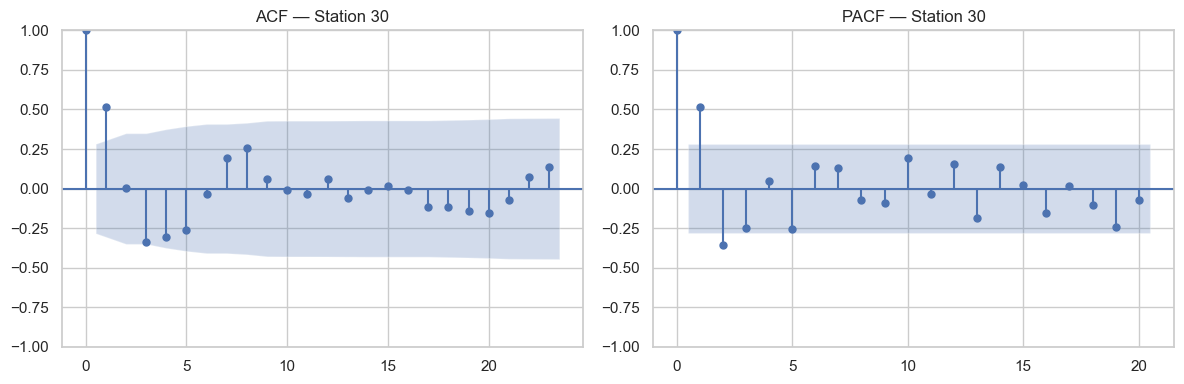

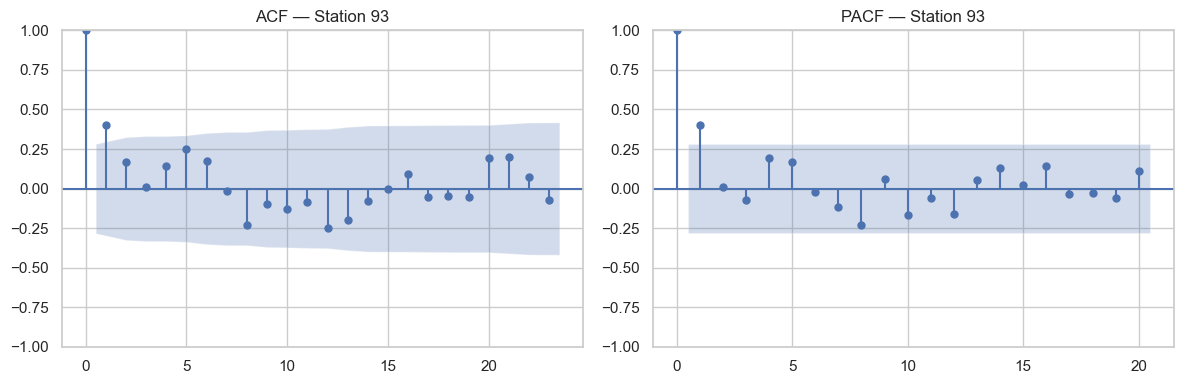

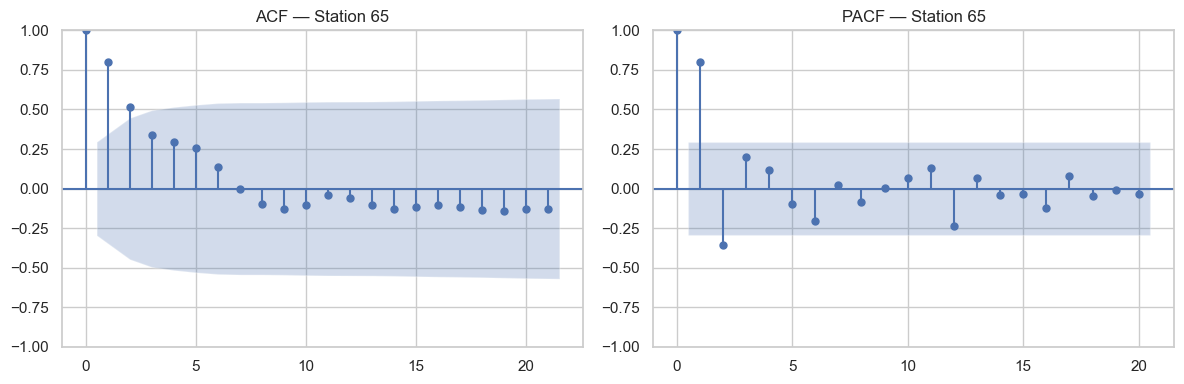

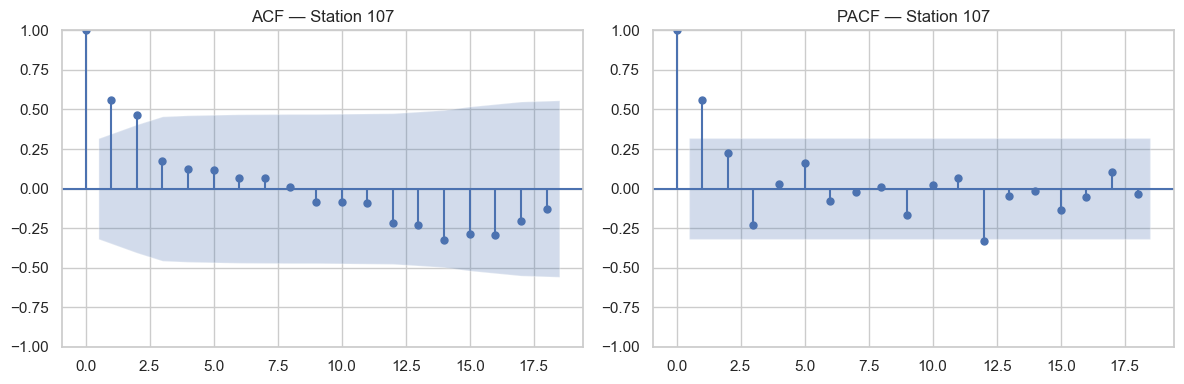

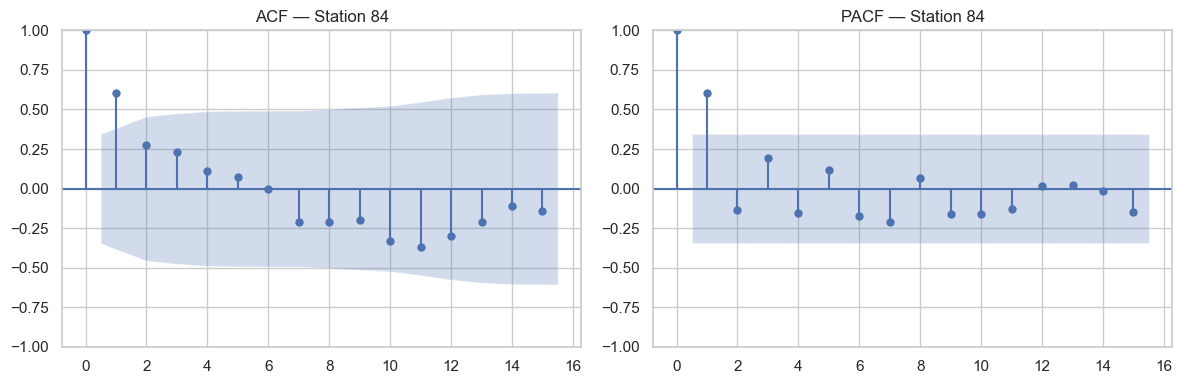

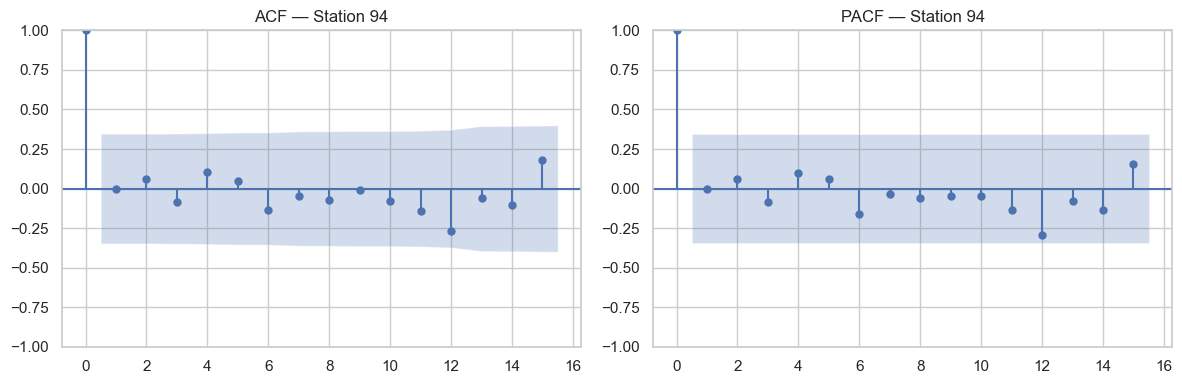


5.2.3 — MONTHLY PM2.5 DRIFT


,month,observations,median,q1,q3,IQR,above_25_count,above_25_percentage,above_50_count,above_50_percentage
0,2016-11,4.0,2.675,2.550,4.979,2.429,0.0,0.000,0.0,0.000
1,2016-12,107.0,10.200,7.250,14.192,6.942,2.0,1.869,0.0,0.000
2,2017-01,24.0,6.183,4.542,9.383,4.842,0.0,0.000,0.0,0.000
3,2017-02,95.0,10.865,8.705,15.091,6.386,2.0,2.105,0.0,0.000
4,2017-03,164.0,7.818,4.589,12.969,8.379,4.0,2.439,1.0,0.610
...,...,...,...,...,...,...,...,...,...,...
99,2025-12,480.0,10.000,6.269,17.507,11.238,45.0,9.375,1.0,0.208
100,2026-01,524.0,6.000,3.291,11.000,7.709,18.0,3.435,1.0,0.191
101,2026-02,450.0,6.000,2.685,12.000,9.315,46.0,10.222,10.0,2.222
102,2026-03,455.0,9.245,4.365,17.250,12.885,47.0,10.330,7.0,1.538



YEARLY PM2.5 DRIFT


,year,observations,median,q1,q3,IQR,above_25_count,above_25_percentage,above_50_count,above_50_percentage
0,2016,111.0,10.167,6.944,14.000,7.056,2.0,1.802,0.0,0.000
1,2017,2116.0,7.667,4.643,11.940,7.297,81.0,3.828,7.0,0.331
2,2018,252.0,7.019,4.440,10.612,6.172,1.0,0.397,0.0,0.000
3,2019,1772.0,6.718,3.000,12.387,9.387,76.0,4.289,1.0,0.056
4,2020,3247.0,5.714,3.233,9.793,6.560,67.0,2.063,3.0,0.092
5,2021,4746.0,6.800,3.714,11.141,7.427,113.0,2.381,28.0,0.590
6,2022,4954.0,8.125,4.800,12.165,7.365,100.0,2.019,23.0,0.464
7,2023,5400.0,9.000,5.791,13.225,7.434,132.0,2.444,11.0,0.204
8,2024,8688.0,8.000,5.070,12.000,6.930,274.0,3.154,18.0,0.207
9,2025,8149.0,8.522,5.455,12.616,7.161,264.0,3.240,8.0,0.098


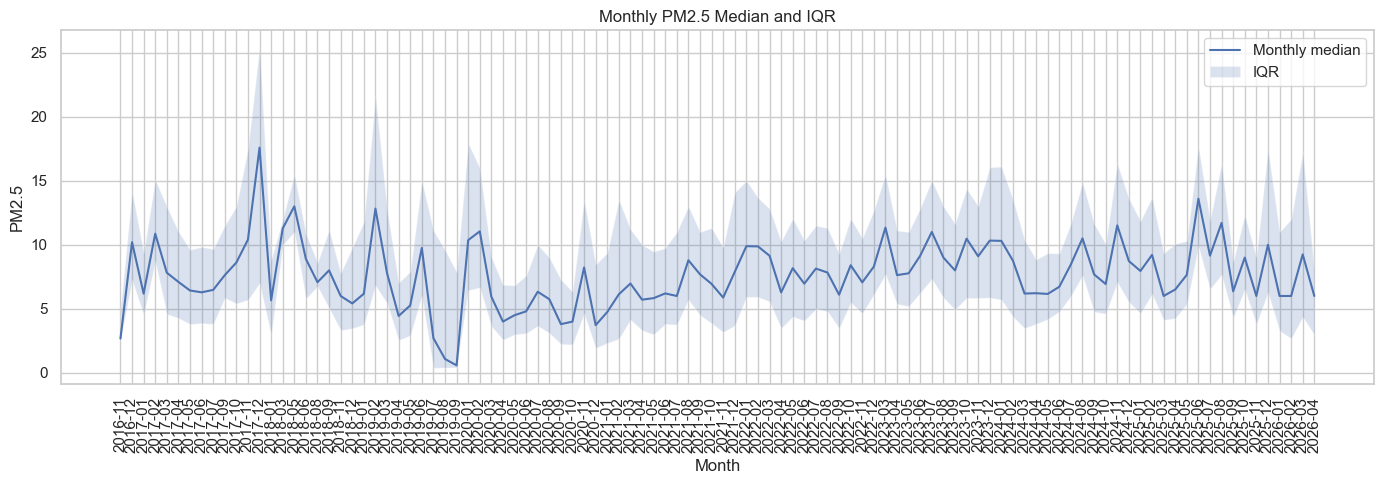

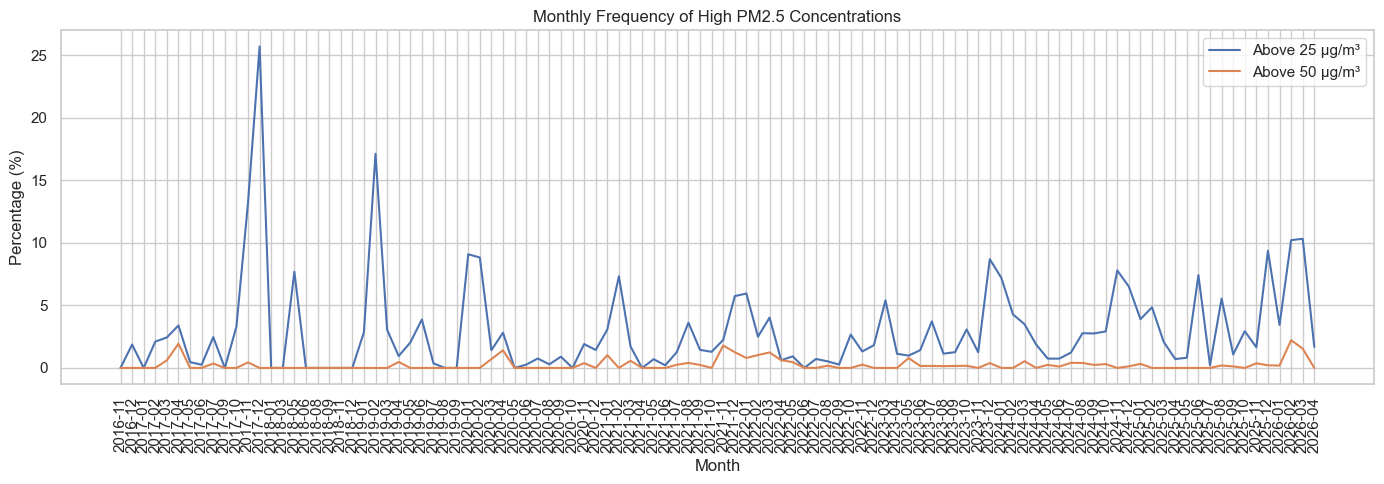

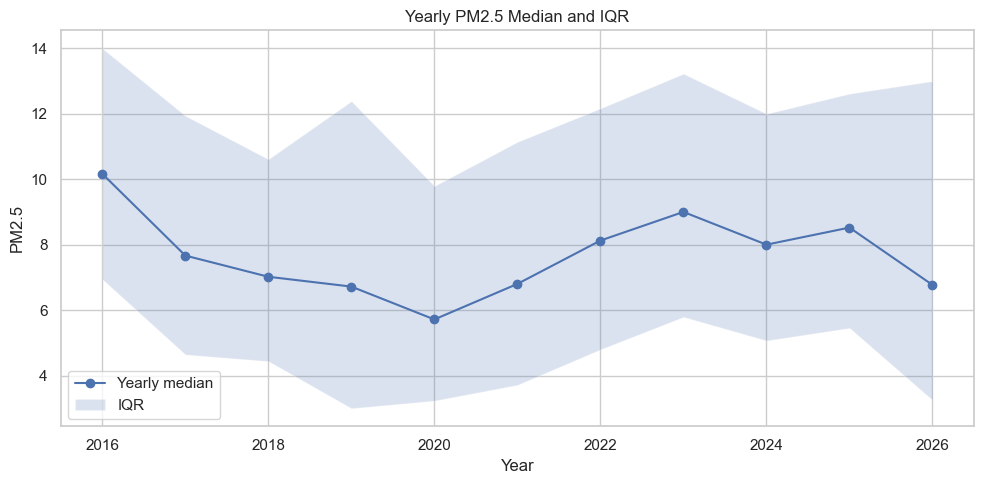

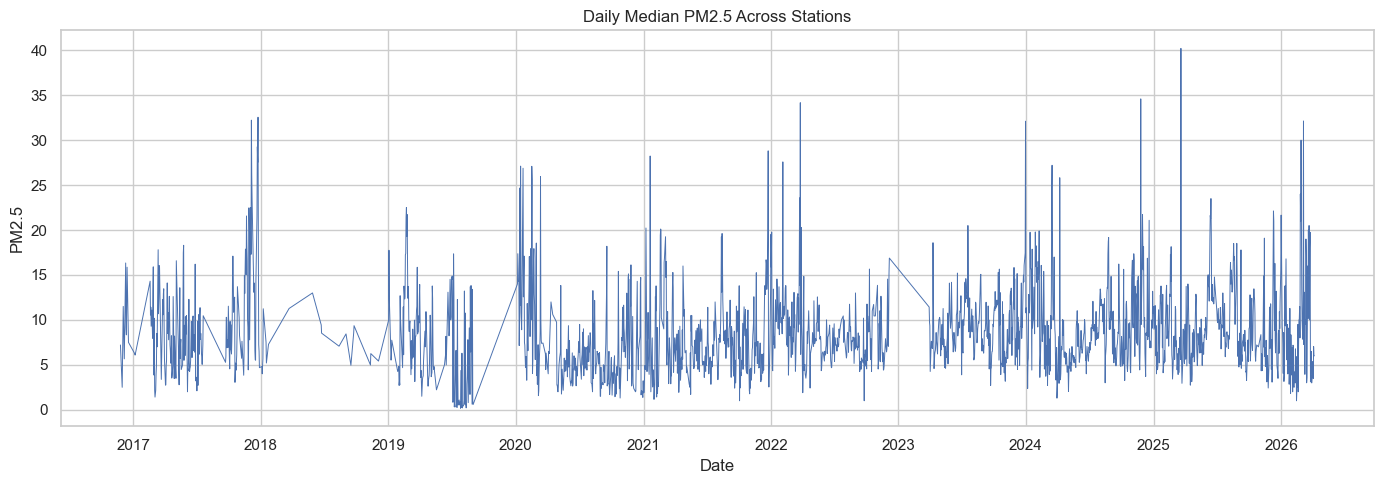


5.2.4 — MONTH-OF-YEAR PATTERN


,month_number,observations,median,q1,q3,month_name
0,1,3032,8.145,4.336,13.234,January
1,2,3113,9.250,5.000,14.391,February
2,3,2752,7.257,4.420,12.000,March
3,4,2998,6.439,3.943,9.809,April
4,5,3526,6.873,4.301,10.025,May
5,6,4154,7.812,4.906,12.000,June
6,7,4288,8.301,5.050,11.965,July
7,8,4324,9.362,6.000,13.852,August
8,9,3591,7.000,4.147,10.103,September
9,10,3043,7.800,4.690,11.833,October


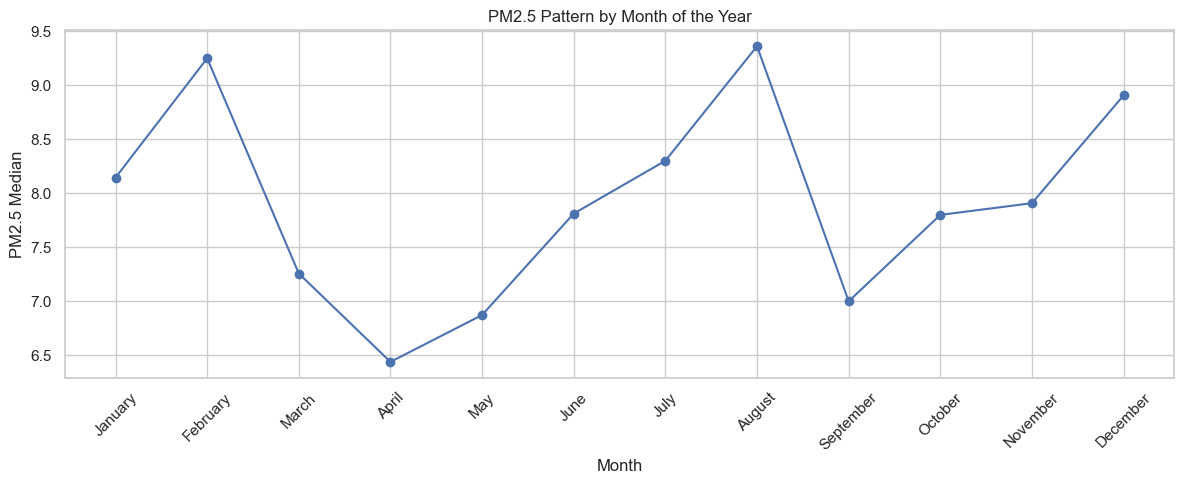


SEASONAL PM2.5 PATTERN


,season,observations,median,q1,q3
0,Winter,8938,8.773,4.800,14.087
1,Spring,9276,6.833,4.167,10.500
2,Summer,12766,8.500,5.209,12.559
3,Autumn,10003,7.470,4.500,11.500


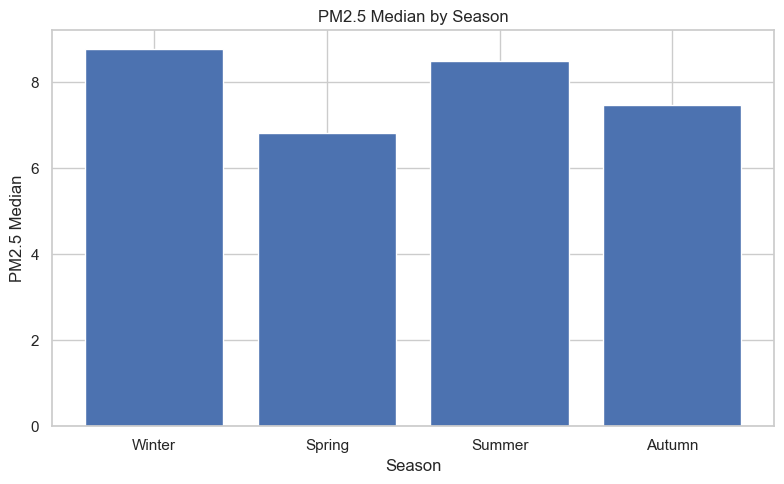


SEASONAL MEDIANS OF ATMOSPHERIC PREDICTORS


,AOD,NO2,CO,O3,temperature_celsius,pressure_mb,wind_u,wind_v,wind_speed
season,,,,,,,,,
Winter,0.081,0.0001,0.0319,0.1446,11.0409,1002.2864,0.9013,-0.5148,1.9649
Spring,0.135,0.0001,0.0334,0.1559,15.7940,996.9317,0.2051,0.0902,1.5482
Summer,0.168,0.0001,0.0305,0.1389,25.2957,995.2617,-0.4424,0.4603,1.6402
Autumn,0.119,0.0001,0.0301,0.1318,18.7976,998.9402,0.2882,-0.1302,1.6324


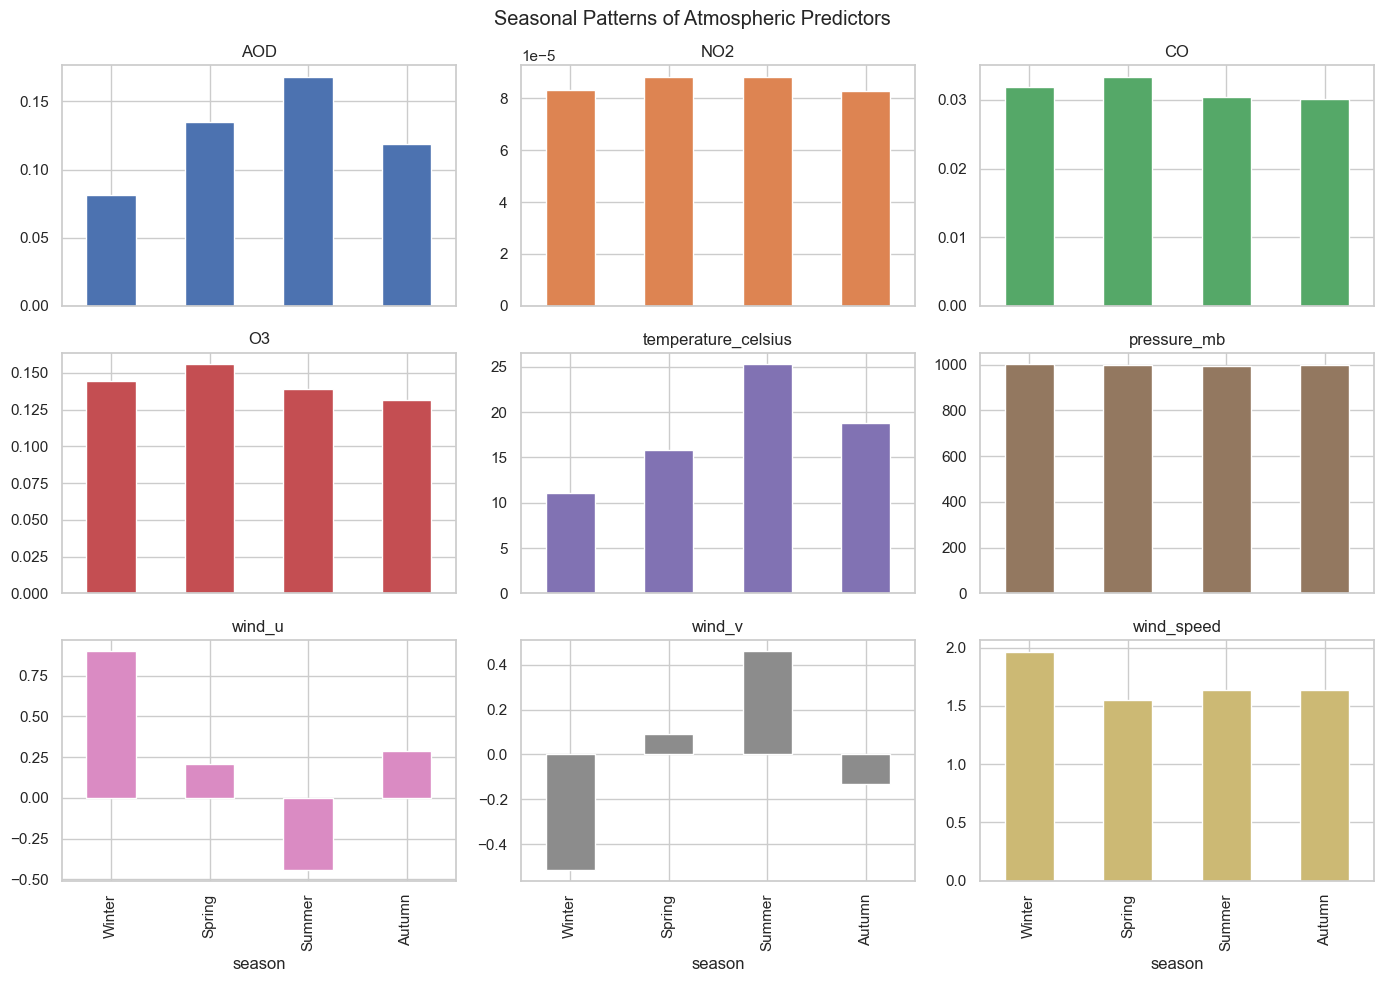


STATION-LEVEL SEASONAL PM2.5 MEDIANS


season,Winter,Spring,Summer,Autumn
id,,,,
0,10.715,7.976,7.000,7.598
1,4.000,5.500,5.604,6.000
10,4.083,5.045,9.895,6.250
100,6.506,5.133,7.444,5.721
101,3.722,3.823,3.905,3.000
...,...,...,...,...
95,5.242,4.382,NaN,NaN
96,3.000,7.000,NaN,NaN
97,7.909,6.435,8.667,7.271



5.2.5 — LEAD-LAG RELATIONSHIPS

Median correlation across stations for each predictor and lag:


,predictor,lag_days,median,mean,count
0,AOD,-7,-0.0246,-0.0083,83
1,AOD,-6,-0.0050,0.0287,84
2,AOD,-5,0.0184,0.0258,81
3,AOD,-4,0.0288,0.0401,82
4,AOD,-3,0.0543,0.0602,83
...,...,...,...,...,...
130,wind_v,3,-0.0287,-0.0227,83
131,wind_v,4,-0.0019,-0.0179,82
132,wind_v,5,-0.0092,-0.0069,81
133,wind_v,6,-0.0111,-0.0174,84


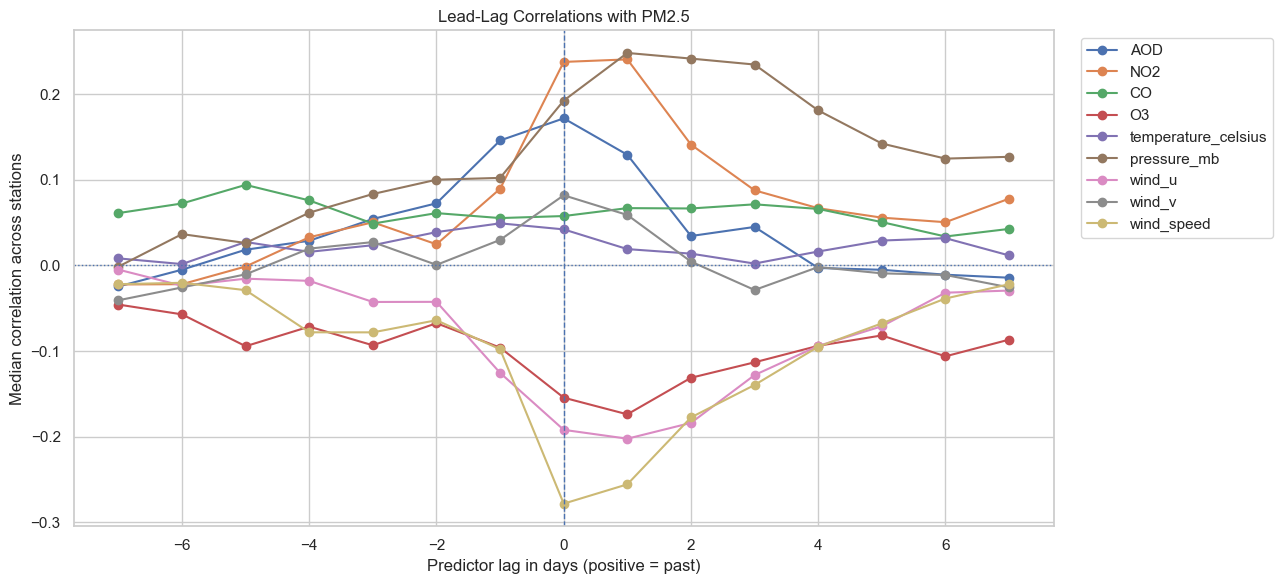


SECTION 5.2 COMPLETED
Number of stations analysed: 95
Final CSV saved: Exploratory_temporal.csv
No intermediate CSV files were created.

Final temporal dataset preview:


,model_id,model_group,variable,node_id,n_records,t_min,t_max,sampling_interval_median_sec,sampling_interval_std_sec,pct_missing_intervals,...,pct_days_above_25,pct_days_above_50,regime_breaks,cv_strategy_recommended,gap_between_train_test_sec,n_cycles_observed,no2_pct_missing_by_month,co_pct_missing_by_month,o3_pct_missing_by_month,notes
0,,,pm25,0,727,2016-12-07,2022-03-12,86400.0,6.546300e+05,62.1748,...,1.7882,0.1376,,,NaN,NaN,,,,"ACF, PACF, Ljung-Box and ADF calculated on the..."
1,,,pm25,1,447,2016-11-25,2025-09-04,86400.0,2.210210e+06,86.0574,...,0.8949,0.6711,,,NaN,NaN,,,,"ACF, PACF, Ljung-Box and ADF calculated on the..."
2,,,pm25,10,346,2018-01-17,2025-09-24,86400.0,2.758194e+06,87.6781,...,0.8671,0.5780,,,NaN,NaN,,,,"ACF, PACF, Ljung-Box and ADF calculated on the..."
3,,,pm25,100,442,2024-01-28,2026-02-09,86400.0,1.241979e+05,40.5914,...,0.6787,0.0000,,,NaN,NaN,,,,"ACF, PACF, Ljung-Box and ADF calculated on the..."
4,,,pm25,101,771,2016-12-02,2023-04-12,86400.0,9.009593e+05,66.8102,...,0.5188,0.0000,,,NaN,NaN,,,,"ACF, PACF, Ljung-Box and ADF calculated on the..."


In [ ]:
# ============================================================
# SECTION 5.2 — TIME-SERIES EXPLORATION
# Only one CSV will be saved: exploratory_temporal.csv
# All other results will be displayed in the notebook.
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import acf, pacf, adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# 0. PREPARATION
# ------------------------------------------------------------

data = combined_clean.copy()

required_columns = [
    "date",
    "id",
    "pm25",
    "AOD",
    "NO2",
    "CO",
    "O3",
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
]

missing_columns = [c for c in required_columns if c not in data.columns]

if missing_columns:
    raise ValueError(f"Missing columns in combined_clean: {missing_columns}")

data["date"] = pd.to_datetime(data["date"], errors="coerce").dt.normalize()

numeric_columns = [
    "pm25",
    "AOD",
    "NO2",
    "CO",
    "O3",
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
]

for col in numeric_columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.dropna(subset=["date", "id", "pm25"]).copy()

data = data[(data["pm25"] > 0) & (data["pm25"] < 500)].copy()

data["id"] = data["id"].astype(str)

# Wind speed derived from the two wind components.
data["wind_speed"] = np.sqrt(data["wind_u"] ** 2 + data["wind_v"] ** 2)

predictors = [
    "AOD",
    "NO2",
    "CO",
    "O3",
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
    "wind_speed",
]

# Check duplicate station-date records.
duplicates = data.duplicated(subset=["id", "date"]).sum()

print("=" * 60)
print("SECTION 5.2 — DATA VALIDATION")
print("=" * 60)

print("Total observations:", len(data))
print("Number of stations:", data["id"].nunique())
print("Date range:", data["date"].min(), "to", data["date"].max())
print("Duplicate station-date records:", duplicates)

if duplicates > 0:
    raise ValueError(
        "Duplicate (id, date) records exist. " "Inspect them before continuing."
    )


# ------------------------------------------------------------
# 5.2.1 — TIMESTAMP REGULARITY
# ------------------------------------------------------------

timestamp_results = []

for station_id, group in data.groupby("id"):

    group = group.sort_values("date")
    dates = group["date"].drop_duplicates()

    first_date = dates.min()
    last_date = dates.max()

    expected_days = (last_date - first_date).days + 1
    observed_days = len(dates)
    missing_days = expected_days - observed_days

    intervals = dates.diff().dt.total_seconds().dropna()

    timestamp_results.append(
        {
            "station_id": station_id,
            "first_date": first_date,
            "last_date": last_date,
            "observed_days": observed_days,
            "expected_days": expected_days,
            "missing_days": missing_days,
            "missing_percentage": (
                missing_days / expected_days * 100 if expected_days else np.nan
            ),
            "median_interval_days": (
                intervals.median() / 86400 if len(intervals) else np.nan
            ),
            "interval_std_days": (
                intervals.std() / 86400 if len(intervals) > 1 else np.nan
            ),
            "one_day_intervals": int((intervals == 86400).sum()),
            "irregular_intervals": int((intervals > 86400).sum()),
            "longest_interval_days": (
                intervals.max() / 86400 if len(intervals) else np.nan
            ),
        }
    )

timestamp_table = pd.DataFrame(timestamp_results)

print("\n" + "=" * 60)
print("5.2.1 — TIMESTAMP REGULARITY")
print("=" * 60)

print("\nOverall timestamp summary:")

print(
    timestamp_table[
        [
            "observed_days",
            "expected_days",
            "missing_days",
            "missing_percentage",
            "median_interval_days",
            "longest_interval_days",
        ]
    ]
    .describe()
    .round(2)
)

print("\nStations with the most missing days:")

display(
    timestamp_table.sort_values("missing_percentage", ascending=False).head(10).round(2)
)

print("\nDistribution of median sampling intervals:")

display(
    timestamp_table["median_interval_days"]
    .value_counts()
    .sort_index()
    .rename_axis("median_interval_days")
    .reset_index(name="number_of_stations")
)


# ------------------------------------------------------------
# 5.2.2 — ACF, PACF, LJUNG-BOX, ADF AND KPSS
# ------------------------------------------------------------


def longest_continuous_segment(group):
    """
    Return the longest sequence of consecutive calendar days
    with observed PM2.5 values.
    """

    series = group.set_index("date")["pm25"].sort_index().asfreq("D")

    valid = series.notna()

    if not valid.any():
        return pd.Series(dtype=float)

    segment_id = valid.ne(valid.shift(fill_value=False)).cumsum()

    valid_segments = [
        series.loc[valid & (segment_id == sid)] for sid in segment_id[valid].unique()
    ]

    return max(valid_segments, key=len)


station_ts_results = []
segments_for_plots = {}

for station_id, group in data.groupby("id"):

    segment = longest_continuous_segment(group)

    segments_for_plots[station_id] = segment

    result = {
        "station_id": station_id,
        "continuous_segment_days": len(segment),
        "acf_lag1": np.nan,
        "acf_lag7": np.nan,
        "acf_lag24": np.nan,
        "pacf_lag1": np.nan,
        "ljung_box_p": np.nan,
        "adf_p": np.nan,
        "kpss_p": np.nan,
    }

    # At least 30 consecutive observations.
    if len(segment) >= 30:

        values = segment.to_numpy()

        # ACF
        try:
            acf_values = acf(values, nlags=24, fft=True)

            result["acf_lag1"] = acf_values[1]
            result["acf_lag7"] = acf_values[7]
            result["acf_lag24"] = acf_values[24]

        except Exception:
            pass

        # PACF
        try:
            max_pacf_lag = min(12, (len(values) - 1) // 2)

            pacf_values = pacf(values, nlags=max_pacf_lag, method="ywm")

            result["pacf_lag1"] = pacf_values[1]

        except Exception:
            pass

        # Ljung-Box
        try:
            lb_lag = min(10, len(values) // 5)

            if lb_lag >= 1:

                lb_result = acorr_ljungbox(values, lags=[lb_lag], return_df=True)

                result["ljung_box_p"] = lb_result["lb_pvalue"].iloc[0]

        except Exception:
            pass

        # ADF
        try:
            result["adf_p"] = adfuller(values, autolag="AIC")[1]

        except Exception:
            pass

        # KPSS
        try:
            result["kpss_p"] = kpss(values, regression="c", nlags="auto")[1]

        except Exception:
            pass

    station_ts_results.append(result)


ts_table = pd.DataFrame(station_ts_results)

print("\n" + "=" * 60)
print("5.2.2 — ACF, PACF, LJUNG-BOX, ADF AND KPSS")
print("=" * 60)

print("\nStations with the longest continuous segments:")

display(
    ts_table.sort_values("continuous_segment_days", ascending=False).head(10).round(4)
)

print("\nSummary of ACF and PACF results:")

display(
    ts_table[["acf_lag1", "acf_lag7", "acf_lag24", "pacf_lag1"]].describe().round(4)
)

print("\nLjung-Box p-value summary:")
display(ts_table["ljung_box_p"].describe().round(4))

print("\nADF p-value summary:")
display(ts_table["adf_p"].describe().round(4))

print("\nKPSS p-value summary:")
display(ts_table["kpss_p"].describe().round(4))


# Plot ACF and PACF for the six stations with the longest segments.

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

top_stations = (
    ts_table.sort_values("continuous_segment_days", ascending=False)
    .head(6)["station_id"]
    .tolist()
)

for station_id in top_stations:

    segment = segments_for_plots[station_id]

    if len(segment) < 30:
        continue

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    plot_acf(segment, lags=min(30, len(segment) // 2 - 1), ax=axes[0])

    plot_pacf(segment, lags=min(20, (len(segment) - 1) // 2), method="ywm", ax=axes[1])

    axes[0].set_title(f"ACF — Station {station_id}")

    axes[1].set_title(f"PACF — Station {station_id}")

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 5.2.3 — PM2.5 DRIFT ACROSS MONTHS AND YEARS
# ------------------------------------------------------------

data["month"] = data["date"].dt.to_period("M")
data["year"] = data["date"].dt.year


def summarize_pm25(group):

    return pd.Series(
        {
            "observations": group["pm25"].count(),
            "median": group["pm25"].median(),
            "q1": group["pm25"].quantile(0.25),
            "q3": group["pm25"].quantile(0.75),
            "IQR": (group["pm25"].quantile(0.75) - group["pm25"].quantile(0.25)),
            "above_25_count": (group["pm25"] > 25).sum(),
            "above_25_percentage": (group["pm25"] > 25).mean() * 100,
            "above_50_count": (group["pm25"] > 50).sum(),
            "above_50_percentage": (group["pm25"] > 50).mean() * 100,
        }
    )


monthly_drift = data.groupby("month").apply(summarize_pm25).reset_index()

yearly_drift = data.groupby("year").apply(summarize_pm25).reset_index()

monthly_drift["month"] = monthly_drift["month"].astype(str)

print("\n" + "=" * 60)
print("5.2.3 — MONTHLY PM2.5 DRIFT")
print("=" * 60)

display(monthly_drift.round(3))

print("\nYEARLY PM2.5 DRIFT")

display(yearly_drift.round(3))


# Monthly median and IQR.

plt.figure(figsize=(14, 5))

plt.plot(monthly_drift["month"], monthly_drift["median"], label="Monthly median")

plt.fill_between(
    range(len(monthly_drift)),
    monthly_drift["q1"],
    monthly_drift["q3"],
    alpha=0.2,
    label="IQR",
)

plt.xticks(range(len(monthly_drift)), monthly_drift["month"], rotation=90)

plt.title("Monthly PM2.5 Median and IQR")
plt.xlabel("Month")
plt.ylabel("PM2.5")
plt.legend()
plt.tight_layout()
plt.show()


# Frequency of high-concentration observations by month.

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_drift["month"], monthly_drift["above_25_percentage"], label="Above 25 µg/m³"
)

plt.plot(
    monthly_drift["month"], monthly_drift["above_50_percentage"], label="Above 50 µg/m³"
)

plt.xticks(rotation=90)
plt.title("Monthly Frequency of High PM2.5 Concentrations")
plt.xlabel("Month")
plt.ylabel("Percentage (%)")
plt.legend()
plt.tight_layout()
plt.show()


# Yearly median and IQR.

plt.figure(figsize=(10, 5))

plt.plot(
    yearly_drift["year"], yearly_drift["median"], marker="o", label="Yearly median"
)

plt.fill_between(
    yearly_drift["year"], yearly_drift["q1"], yearly_drift["q3"], alpha=0.2, label="IQR"
)

plt.title("Yearly PM2.5 Median and IQR")
plt.xlabel("Year")
plt.ylabel("PM2.5")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5.2.4 — DAILY, MONTHLY AND SEASONAL PATTERNS
# ------------------------------------------------------------

# Pooled daily median across station observations.

daily_pattern = data.groupby("date")["pm25"].median().reset_index()

plt.figure(figsize=(14, 5))

plt.plot(daily_pattern["date"], daily_pattern["pm25"], linewidth=0.7)

plt.title("Daily Median PM2.5 Across Stations")
plt.xlabel("Date")
plt.ylabel("PM2.5")
plt.tight_layout()
plt.show()


# Month-of-year pattern.

data["month_number"] = data["date"].dt.month

month_names = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December",
}

month_pattern = (
    data.groupby("month_number")["pm25"]
    .agg(
        observations="count",
        median="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
    )
    .reset_index()
)

month_pattern["month_name"] = month_pattern["month_number"].map(month_names)

print("\n" + "=" * 60)
print("5.2.4 — MONTH-OF-YEAR PATTERN")
print("=" * 60)

display(month_pattern.round(3))

plt.figure(figsize=(12, 5))

plt.plot(month_pattern["month_name"], month_pattern["median"], marker="o")

plt.title("PM2.5 Pattern by Month of the Year")
plt.xlabel("Month")
plt.ylabel("PM2.5 Median")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Seasonal pattern.


def get_season(month):

    if month in [12, 1, 2]:
        return "Winter"

    elif month in [3, 4, 5]:
        return "Spring"

    elif month in [6, 7, 8]:
        return "Summer"

    else:
        return "Autumn"


data["season"] = data["date"].dt.month.map(get_season)

season_order = ["Winter", "Spring", "Summer", "Autumn"]

season_pattern = (
    data.groupby("season")["pm25"]
    .agg(
        observations="count",
        median="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
    )
    .reindex(season_order)
    .reset_index()
)

print("\nSEASONAL PM2.5 PATTERN")

display(season_pattern.round(3))

plt.figure(figsize=(8, 5))

plt.bar(season_pattern["season"], season_pattern["median"])

plt.title("PM2.5 Median by Season")
plt.xlabel("Season")
plt.ylabel("PM2.5 Median")
plt.tight_layout()
plt.show()


# Seasonal patterns of atmospheric predictors.

seasonal_predictors = data.groupby("season")[predictors].median().reindex(season_order)

print("\nSEASONAL MEDIANS OF ATMOSPHERIC PREDICTORS")

display(seasonal_predictors.round(4))

seasonal_predictors.plot(
    kind="bar", subplots=True, layout=(3, 3), figsize=(14, 10), legend=False
)

plt.suptitle("Seasonal Patterns of Atmospheric Predictors")
plt.tight_layout()
plt.show()


# Station-level seasonal PM2.5 medians.

station_seasonal = (
    data.groupby(["id", "season"])["pm25"]
    .median()
    .unstack()
    .reindex(columns=season_order)
)

print("\nSTATION-LEVEL SEASONAL PM2.5 MEDIANS")

display(station_seasonal.round(3))


# ------------------------------------------------------------
# 5.2.5 — LEAD-LAG RELATIONSHIPS
# ------------------------------------------------------------

# Positive lag: predictor values from previous days.
# Negative lag: predictor values from future days.
# Zero lag: predictor and PM2.5 from the same day.

lead_lag_results = []

for station_id, group in data.groupby("id"):

    group = group.sort_values("date")

    daily = group.set_index("date")[["pm25"] + predictors].asfreq("D")

    for predictor in predictors:

        for lag in range(-7, 8):

            shifted_predictor = daily[predictor].shift(lag)

            paired = pd.concat([daily["pm25"], shifted_predictor], axis=1).dropna()

            if len(paired) >= 30:
                correlation = paired.iloc[:, 0].corr(paired.iloc[:, 1])
            else:
                correlation = np.nan

            lead_lag_results.append(
                {
                    "station_id": station_id,
                    "predictor": predictor,
                    "lag_days": lag,
                    "correlation": correlation,
                    "number_of_pairs": len(paired),
                }
            )


lead_lag_table = pd.DataFrame(lead_lag_results)

lead_lag_summary = (
    lead_lag_table.groupby(["predictor", "lag_days"])["correlation"]
    .agg(["median", "mean", "count"])
    .reset_index()
)

print("\n" + "=" * 60)
print("5.2.5 — LEAD-LAG RELATIONSHIPS")
print("=" * 60)

print("\nMedian correlation across stations " "for each predictor and lag:")

display(lead_lag_summary.round(4))


# Plot median correlation for each predictor across lags.

plt.figure(figsize=(13, 6))

for predictor in predictors:

    subset = lead_lag_summary[lead_lag_summary["predictor"] == predictor]

    plt.plot(subset["lag_days"], subset["median"], marker="o", label=predictor)

plt.axvline(0, linestyle="--", linewidth=1)

plt.axhline(0, linestyle=":", linewidth=1)

plt.title("Lead-Lag Correlations with PM2.5")
plt.xlabel("Predictor lag in days (positive = past)")
plt.ylabel("Median correlation across stations")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# FINAL OUTPUT — EXPLORATORY_TEMPORAL.CSV ONLY
# ------------------------------------------------------------


# Monthly missingness function.
# Missing calendar days are also counted as missing observations.


def monthly_missing_percentages(station_data, variable):

    if station_data.empty:
        return ""

    dates = pd.date_range(
        start=station_data["date"].min(), end=station_data["date"].max(), freq="D"
    )

    values = station_data.set_index("date")[variable].reindex(dates)

    monthly_missing = values.isna().groupby(values.index.to_period("M")).mean() * 100

    return "; ".join(
        f"{month}: {percentage:.2f}%" for month, percentage in monthly_missing.items()
    )


final_rows = []

for _, station in timestamp_table.iterrows():

    station_id = station["station_id"]

    ts_row = ts_table[ts_table["station_id"] == station_id].iloc[0]

    station_data = data[data["id"] == station_id].sort_values("date").copy()

    # --------------------------------------------------------
    # Trend calculation
    # --------------------------------------------------------

    trend_slope = np.nan
    trend_pvalue = np.nan

    if len(station_data) >= 3:

        x = (station_data["date"] - station_data["date"].min()).dt.days.to_numpy()

        y = station_data["pm25"].to_numpy()

        if len(np.unique(x)) >= 2:

            try:
                from scipy.stats import linregress

                trend = linregress(x, y)

                trend_slope = trend.slope
                trend_pvalue = trend.pvalue

            except Exception:
                pass

    # --------------------------------------------------------
    # Seasonal amplitude
    # Difference between highest and lowest seasonal median.
    # --------------------------------------------------------

    seasonal_medians = station_data.groupby("season")["pm25"].median()

    seasonal_amplitude = np.nan

    if len(seasonal_medians.dropna()) >= 2:

        seasonal_amplitude = seasonal_medians.max() - seasonal_medians.min()

    # --------------------------------------------------------
    # Number of complete annual cycles
    # A complete year has observations in all 12 months.
    # --------------------------------------------------------

    monthly_coverage = (
        station_data.assign(
            year=station_data["date"].dt.year, month=station_data["date"].dt.month
        )
        .groupby("year")["month"]
        .nunique()
    )

    n_cycles_observed = int((monthly_coverage == 12).sum())

    # --------------------------------------------------------
    # High PM2.5 observations
    # --------------------------------------------------------

    n_above_25 = int((station_data["pm25"] > 25).sum())

    n_above_50 = int((station_data["pm25"] > 50).sum())

    n_observed = len(station_data)

    # --------------------------------------------------------
    # Create one CSV row per station
    # --------------------------------------------------------

    final_rows.append(
        {
            "model_id": "MLP",
            "model_group": "G9",
            "variable": "pm25",
            "node_id": station_id,
            "n_records": n_observed,
            "t_min": station_data["date"].min(),
            "t_max": station_data["date"].max(),
            "sampling_interval_median_sec": (
                station["median_interval_days"] * 86400
                if pd.notna(station["median_interval_days"])
                else np.nan
            ),
            "sampling_interval_std_sec": (
                station["interval_std_days"] * 86400
                if pd.notna(station["interval_std_days"])
                else np.nan
            ),
            "pct_missing_intervals": (station["missing_percentage"]),
            "acf_lag1": ts_row["acf_lag1"],
            "acf_lag7": ts_row["acf_lag7"],
            "acf_lag24": ts_row["acf_lag24"],
            "pacf_lag1": ts_row["pacf_lag1"],
            "ljung_box_p": ts_row["ljung_box_p"],
            "adf_p": ts_row["adf_p"],
            "kpss_p": ts_row["kpss_p"],
            "trend_slope_per_day": trend_slope,
            "trend_pval": trend_pvalue,
            # Daily data: diurnal amplitude is not applicable.
            "diurnal_amplitude": np.nan,
            "seasonal_amplitude": seasonal_amplitude,
            # No independent target drift test was performed.
            "target_drift_stat": np.nan,
            "target_drift_pval": np.nan,
            "n_days_above_25": n_above_25,
            "n_days_above_50": n_above_50,
            "pct_days_above_25": (
                n_above_25 / n_observed * 100 if n_observed else np.nan
            ),
            "pct_days_above_50": (
                n_above_50 / n_observed * 100 if n_observed else np.nan
            ),
            # Change-point detection was not performed.
            "regime_breaks": "",
            "cv_strategy_recommended": (
                "Temporal CV primary; "
                "Spatial GroupKFold supplementary; "
                "Random CV diagnostic only"
            ),
            # Not calculated as a separate gap metric here.
            "gap_between_train_test_sec": np.nan,
            "n_cycles_observed": n_cycles_observed,
            "no2_pct_missing_by_month": (
                monthly_missing_percentages(station_data, "NO2")
            ),
            "co_pct_missing_by_month": (
                monthly_missing_percentages(station_data, "CO")
            ),
            "o3_pct_missing_by_month": (
                monthly_missing_percentages(station_data, "O3")
            ),
            "notes": (
                "ACF, PACF, Ljung-Box, ADF and KPSS calculated "
                "on the longest continuous daily PM2.5 segment. "
                "Daily data; diurnal amplitude not applicable. "
                "Monthly missing percentages include absent "
                "calendar days. Seasonal amplitude is the "
                "difference between the highest and lowest "
                "seasonal PM2.5 medians. Target drift test and "
                "regime-break detection not calculated separately. "
                "Gap between train and test not reported."
            ),
        }
    )


# ------------------------------------------------------------
# FINAL CSV STRUCTURE
# ------------------------------------------------------------

final_columns = [
    "model_id",
    "model_group",
    "variable",
    "node_id",
    "n_records",
    "t_min",
    "t_max",
    "sampling_interval_median_sec",
    "sampling_interval_std_sec",
    "pct_missing_intervals",
    "acf_lag1",
    "acf_lag7",
    "acf_lag24",
    "pacf_lag1",
    "ljung_box_p",
    "adf_p",
    "kpss_p",
    "trend_slope_per_day",
    "trend_pval",
    "diurnal_amplitude",
    "seasonal_amplitude",
    "target_drift_stat",
    "target_drift_pval",
    "n_days_above_25",
    "n_days_above_50",
    "pct_days_above_25",
    "pct_days_above_50",
    "regime_breaks",
    "cv_strategy_recommended",
    "gap_between_train_test_sec",
    "n_cycles_observed",
    "no2_pct_missing_by_month",
    "co_pct_missing_by_month",
    "o3_pct_missing_by_month",
    "notes",
]


final_temporal = pd.DataFrame(final_rows, columns=final_columns)


# ------------------------------------------------------------
# SAVE CSV
# ------------------------------------------------------------

os.makedirs("../results", exist_ok=True)

output_path = os.path.abspath(os.path.join("..", "results", "Exploratory_temporal.csv"))

final_temporal.to_csv(output_path, index=False, encoding="utf-8-sig")


# ------------------------------------------------------------
# FINAL VERIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SECTION 5.2 COMPLETED")
print("=" * 60)

print("Number of stations analysed:", len(final_temporal))

print("Final CSV saved:", output_path)
print("File exists:", os.path.exists(output_path))

print("Number of CSV columns:", len(final_temporal.columns))

print("\nMissing values per column:")

display(final_temporal.isna().sum().to_frame("Missing values"))

print("\nFinal temporal dataset preview:")

display(final_temporal.head().round(4))

print("\nMonthly missingness preview:")

display(
    final_temporal[
        [
            "node_id",
            "no2_pct_missing_by_month",
            "co_pct_missing_by_month",
            "o3_pct_missing_by_month",
        ]
    ].head()
)

print("\nNo intermediate CSV files were created.")

## PM2.5 time-series statistics (for Exploratory_Data.csv)

In [ ]:
# ============================================================
# 4. TIME-SERIES STATISTICS FOR PM2.5
# ============================================================

print("\nCalculating summary time-series statistics...")

# These results come from Cell 37.
# They were calculated using eligible continuous daily
# PM2.5 segments for individual stations.

time_series_columns = ["acf_lag1", "acf_lag24", "pacf_lag1", "adf_p"]

pm25_time_series_results = {}

for column in time_series_columns:

    if column in ts_table.columns:

        # Calculate the median separately for each statistic.
        pm25_time_series_results[column] = pd.to_numeric(
            ts_table[column], errors="coerce"
        ).median()

    else:
        pm25_time_series_results[column] = np.nan


# ============================================================
# 5. RECOMMENDED NUMBER OF LAGS USING PACF
# ============================================================

print("Calculating recommended number of lags...")

recommended_lags_per_station = []

for station_id, segment in segments_for_plots.items():

    values = pd.to_numeric(segment, errors="coerce").dropna().to_numpy()

    # Use only segments with at least 30 observations.
    if len(values) < 30:
        continue

    try:

        max_lag = min(12, (len(values) - 1) // 2)

        pacf_values = pacf(values, nlags=max_lag, method="ywm")

        # Approximate 95% confidence limit.
        confidence_limit = 1.96 / np.sqrt(len(values))

        significant = np.abs(pacf_values[1:]) > confidence_limit

        # Count consecutive significant lags starting at lag 1.
        recommended_lag = 0

        for is_significant in significant:

            if is_significant:
                recommended_lag += 1
            else:
                break

        recommended_lags_per_station.append(recommended_lag)

    except Exception as error:

        print(f"PACF calculation skipped for station {station_id}: " f"{error}")


if recommended_lags_per_station:

    pm25_time_series_results["n_lags_recommended"] = int(
        np.median(recommended_lags_per_station)
    )

else:

    pm25_time_series_results["n_lags_recommended"] = np.nan


# ============================================================
# 6. DISPLAY THE RESULTS
# ============================================================

print("\n" + "=" * 65)
print("CALCULATION SUMMARY")
print("=" * 65)

print("\nPM2.5 time-series summary:")
display(pd.DataFrame([pm25_time_series_results]).round(4))

print("\nAdditional calculations completed successfully.")

In [ ]:
# Write the PM2.5 time-series statistics into the pm25 row of results/Exploratory_Data.csv
# (the file is created by 01_eda.ipynb)
exploratory_path = f"{RESULTS_DIR}/Exploratory_Data.csv"
exploratory_data = pd.read_csv(exploratory_path, encoding="utf-8-sig")

pm25_row = exploratory_data["variable"] == "pm25"

for column, value in pm25_time_series_results.items():
    exploratory_data.loc[pm25_row, column] = value

exploratory_data.to_csv(exploratory_path, index=False, encoding="utf-8-sig")

print("Exploratory_Data.csv updated with the PM2.5 time-series statistics.")
display(exploratory_data.loc[pm25_row, ["variable", "acf_lag1", "acf_lag24", "pacf_lag1", "n_lags_recommended", "adf_p"]])


## 5.3.4 Temporal preprocessing and feature engineering

In [ ]:

# ============================================================
# 5.3.4 — TEMPORAL PREPROCESSING AND FEATURE ENGINEERING
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. LOAD THE CLEANED DATASET
# ------------------------------------------------------------

df = pd.read_csv(f"{PROCESSED_DIR}/combined_clean.csv")

print("=" * 65)
print("5.3.4 — TEMPORAL PREPROCESSING AND FEATURE ENGINEERING")
print("=" * 65)

print("\nOriginal dataset shape:", df.shape)

df["date"] = pd.to_datetime(df["date"], errors="coerce")

numeric_columns = [
    "latitude", "longitude", "pm25",
    "AOD", "NO2", "CO", "O3",
    "temperature_celsius", "pressure_mb",
    "wind_u", "wind_v"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")


# ------------------------------------------------------------
# 2. VALIDATE TIMESTAMPS AND IDENTIFIERS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 1 — TIMESTAMP AND IDENTIFIER VALIDATION")
print("=" * 65)

print("Invalid dates before removal:", df["date"].isna().sum())
print("Missing station IDs:", df["id"].isna().sum())
print("Missing PM2.5 values:", df["pm25"].isna().sum())

df = df.dropna(subset=["date", "id", "pm25"]).copy()

df = df[
    (df["pm25"] > 0) &
    (df["pm25"] < 500)
].copy()

df["id"] = df["id"].astype(str)

df = df.sort_values(
    ["id", "date"]
).reset_index(drop=True)

print("\nDate range:", df["date"].min(), "to", df["date"].max())
print("Number of observations:", len(df))
print("Number of GEE IDs:", df["id"].nunique())

duplicate_count = df.duplicated(
    subset=["id", "date"]
).sum()

print("Duplicate (ID, date) records:", duplicate_count)

if duplicate_count > 0:
    raise ValueError(
        "Duplicate records exist for the same station and date. "
        "Resolve them before creating daily timelines."
    )


# ------------------------------------------------------------
# 3. VALIDATE STATION / GEE ID / COORDINATE CONSISTENCY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 2 — STATION AND GEE ID CONSISTENCY")
print("=" * 65)

coordinate_counts = (
    df.groupby("id")[["latitude", "longitude"]]
    .apply(lambda x: x.drop_duplicates().shape[0])
)

sensor_name_counts = (
    df.groupby("id")["sensor_name"]
    .nunique()
)

print(
    "IDs associated with multiple coordinate pairs:",
    (coordinate_counts > 1).sum()
)

print(
    "IDs associated with multiple sensor names:",
    (sensor_name_counts > 1).sum()
)

if (coordinate_counts > 1).any():
    raise ValueError(
        "Some IDs have multiple coordinate pairs. "
        "Investigate these records before continuing."
    )

# NOTE:
# The combined dataset already contains the result of the
# PM2.5-to-GEE matching process.
# We validate the existing association here.
# Independent nearest-coordinate matching requires the
# original separate PM2.5 and GEE source datasets.


# ------------------------------------------------------------
# 4. DECIDE WHICH STATIONS TO RETAIN BEFORE SPLITTING
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 3 — STATION SELECTION")
print("=" * 65)

# Use the same minimum consecutive observation criterion
# identified in Section 5.2.

MIN_CONSECUTIVE_DAYS = 30


def longest_consecutive_run(series):

    valid_dates = pd.DatetimeIndex(
        series.index[series.notna()]
    ).sort_values()

    if len(valid_dates) == 0:
        return 0

    date_differences = (
        valid_dates.to_series().diff().dt.days
    )

    groups = date_differences.ne(1).cumsum()

    run_lengths = (
        valid_dates.to_series()
        .groupby(groups)
        .size()
    )

    return int(run_lengths.max())


station_information = []

for station_id, group in df.groupby("id"):

    group = group.sort_values("date").set_index("date")

    full_dates = pd.date_range(
        start=group.index.min(),
        end=group.index.max(),
        freq="D"
    )

    daily_pm25 = group["pm25"].reindex(full_dates)

    longest_run = longest_consecutive_run(daily_pm25)

    station_information.append({
        "id": station_id,
        "total_observations": int(group["pm25"].count()),
        "longest_consecutive_days": longest_run
    })


station_selection = pd.DataFrame(station_information)

retained_ids = station_selection.loc[
    station_selection["longest_consecutive_days"]
    >= MIN_CONSECUTIVE_DAYS,
    "id"
].tolist()

excluded_ids = station_selection.loc[
    station_selection["longest_consecutive_days"]
    < MIN_CONSECUTIVE_DAYS,
    "id"
].tolist()

print("Stations before selection:", df["id"].nunique())
print("Stations retained:", len(retained_ids))
print("Stations excluded:", len(excluded_ids))

print("\nLongest consecutive observation runs:")

print(
    station_selection.sort_values(
        "longest_consecutive_days",
        ascending=False
    ).head(10).to_string(index=False)
)

if len(retained_ids) == 0:
    raise ValueError(
        "No stations meet the consecutive-day requirement."
    )

# Station selection happens BEFORE splitting
df = df[df["id"].isin(retained_ids)].copy()

print("\nDataset shape after station selection:", df.shape)


# ------------------------------------------------------------
# 5. CREATE A REGULAR DAILY TIMELINE FOR EACH STATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 4 — DAILY TIMELINE CREATION")
print("=" * 65)

daily_station_data = []

for station_id, group in df.groupby("id"):

    group = group.sort_values("date").copy()

    sensor_name = group["sensor_name"].iloc[0]
    latitude = group["latitude"].iloc[0]
    longitude = group["longitude"].iloc[0]

    full_dates = pd.date_range(
        start=group["date"].min(),
        end=group["date"].max(),
        freq="D"
    )

    group = group.set_index("date")

    daily_group = group.reindex(full_dates)

    daily_group.index.name = "date"
    daily_group = daily_group.reset_index()

    daily_group["id"] = station_id
    daily_group["sensor_name"] = sensor_name
    daily_group["latitude"] = latitude
    daily_group["longitude"] = longitude

    daily_group["observed_record"] = (
        daily_group["pm25"].notna()
    )

    daily_station_data.append(daily_group)


daily_df = pd.concat(
    daily_station_data,
    ignore_index=True
)

daily_df = daily_df.sort_values(
    ["id", "date"]
).reset_index(drop=True)

print("Daily timeline shape:", daily_df.shape)
print("Number of stations:", daily_df["id"].nunique())

print(
    "Original observed station-days:",
    int(daily_df["observed_record"].sum())
)

print(
    "Inserted missing calendar days:",
    int((~daily_df["observed_record"]).sum())
)

print(
    "Missing PM2.5 after timeline creation:",
    int(daily_df["pm25"].isna().sum())
)

# Missing dates remain NaN.
# They are NOT replaced by zero or filled using future data.


# ------------------------------------------------------------
# 6. DEFINE CHRONOLOGICAL SPLIT BOUNDARIES
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 5 — CHRONOLOGICAL PERIODS")
print("=" * 65)

TRAIN_END = pd.Timestamp("2024-04-19")
VALIDATION_END = pd.Timestamp("2025-04-03")

daily_df["dataset_split"] = np.select(
    [
        daily_df["date"] <= TRAIN_END,
        daily_df["date"] <= VALIDATION_END
    ],
    [
        "train",
        "validation"
    ],
    default="test"
)

print(
    daily_df.groupby("dataset_split")["date"]
    .agg(["min", "max", "count"])
)


# ------------------------------------------------------------
# 7. CALCULATE HIGH-AOD EVENT THRESHOLD
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 6 — HIGH AOD EVENT THRESHOLD")
print("=" * 65)

# Calculate the threshold using training data only.

training_aod = daily_df.loc[
    (daily_df["dataset_split"] == "train") &
    daily_df["AOD"].notna(),
    "AOD"
]

if len(training_aod) == 0:
    raise ValueError(
        "No training-period AOD values are available."
    )

HIGH_AOD_THRESHOLD = training_aod.quantile(0.90)

print(
    "Training-period AOD 90th percentile:",
    round(HIGH_AOD_THRESHOLD, 5)
)


# ------------------------------------------------------------
# 8. FEATURE ENGINEERING SEPARATELY FOR EACH STATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 7 — TEMPORAL FEATURE ENGINEERING")
print("=" * 65)

engineered_station_data = []

for station_id, group in daily_df.groupby("id"):

    group = group.sort_values("date").copy()
    group = group.set_index("date")


    # --------------------------------------------------------
    # A. DERIVED WIND SPEED
    # --------------------------------------------------------

    group["wind_speed"] = np.sqrt(
        group["wind_u"] ** 2 +
        group["wind_v"] ** 2
    )


    # --------------------------------------------------------
    # B. PM2.5 LAGS AND PAST-ONLY ROLLING STATISTICS
    # --------------------------------------------------------

    group["pm25_lag_1"] = group["pm25"].shift(1)

    past_pm25 = group["pm25"].shift(1)

    group["pm25_roll3_mean"] = (
        past_pm25.rolling(
            window=3,
            min_periods=3
        ).mean()
    )

    group["pm25_roll3_std"] = (
        past_pm25.rolling(
            window=3,
            min_periods=3
        ).std()
    )


    # --------------------------------------------------------
    # C. AOD LAGS
    # --------------------------------------------------------

    for lag in [1, 2, 3]:

        group[f"AOD_lag_{lag}"] = (
            group["AOD"].shift(lag)
        )


    # --------------------------------------------------------
    # D. NO2 LAG
    # --------------------------------------------------------

    group["NO2_lag_1"] = group["NO2"].shift(1)


    # --------------------------------------------------------
    # E. TEMPERATURE AND WIND LAGS
    # --------------------------------------------------------

    group["temperature_lag_1"] = (
        group["temperature_celsius"].shift(1)
    )

    group["wind_speed_lag_1"] = (
        group["wind_speed"].shift(1)
    )


    # --------------------------------------------------------
    # F. DAY-TO-DAY DIFFERENCES
    # --------------------------------------------------------

    # Difference between consecutive days

    group["AOD_diff_1"] = (
        group["AOD"].shift(1) -
        group["AOD"].shift(2)
    )

    # Three-day difference requires four consecutive
    # valid daily AOD observations.

    aod_four_day_count = (
        group["AOD"].shift(1)
        .rolling(window=4, min_periods=4)
        .count()
    )

    group["AOD_diff_3"] = (
        group["AOD"].shift(1) -
        group["AOD"].shift(4)
    ).where(aod_four_day_count == 4)

    group["temperature_diff_1"] = (
        group["temperature_celsius"].shift(1) -
        group["temperature_celsius"].shift(2)
    )

    group["NO2_diff_1"] = (
        group["NO2"].shift(1) -
        group["NO2"].shift(2)
    )


    # --------------------------------------------------------
    # G. AOD RATE OF CHANGE
    # --------------------------------------------------------

    previous_aod_1 = group["AOD"].shift(2)
    previous_aod_3 = group["AOD"].shift(4)

    group["AOD_rate_1"] = (
        group["AOD_diff_1"] / previous_aod_1
    )

    group["AOD_rate_3"] = (
        group["AOD_diff_3"] / previous_aod_3
    )

    group[
        ["AOD_rate_1", "AOD_rate_3"]
    ] = group[
        ["AOD_rate_1", "AOD_rate_3"]
    ].replace([np.inf, -np.inf], np.nan)


    # --------------------------------------------------------
    # H. PAST-ONLY AOD ROLLING STATISTICS
    # --------------------------------------------------------

    past_aod = group["AOD"].shift(1)

    group["AOD_roll3_mean"] = (
        past_aod.rolling(
            window=3,
            min_periods=3
        ).mean()
    )

    group["AOD_roll3_std"] = (
        past_aod.rolling(
            window=3,
            min_periods=3
        ).std()
    )

    group["AOD_roll7_mean"] = (
        past_aod.rolling(
            window=7,
            min_periods=7
        ).mean()
    )

    group["AOD_roll7_std"] = (
        past_aod.rolling(
            window=7,
            min_periods=7
        ).std()
    )

    group["AOD_roll7_max"] = (
        past_aod.rolling(
            window=7,
            min_periods=7
        ).max()
    )


    # --------------------------------------------------------
    # I. TIME SINCE LAST HIGH-AOD EVENT
    # --------------------------------------------------------

    past_aod = group["AOD"].shift(1)

    # Start a new segment whenever previous-day AOD is missing.
    # This prevents carrying an old event across missing periods.

    aod_segment = past_aod.isna().cumsum()

    previous_day_dates = pd.Series(
        group.index - pd.Timedelta(days=1),
        index=group.index
    )

    event_dates = previous_day_dates.where(
        past_aod >= HIGH_AOD_THRESHOLD
    )

    last_event_date = event_dates.groupby(
        aod_segment
    ).ffill()

    group["days_since_high_AOD"] = (
        pd.Series(group.index, index=group.index)
        - last_event_date
    ).dt.days


    # --------------------------------------------------------
    # J. CYCLICAL CALENDAR FEATURES
    # --------------------------------------------------------

    day_of_year = group.index.dayofyear
    month = group.index.month

    group["day_of_year_sin"] = np.sin(
        2 * np.pi * day_of_year / 365.25
    )

    group["day_of_year_cos"] = np.cos(
        2 * np.pi * day_of_year / 365.25
    )

    group["month_sin"] = np.sin(
        2 * np.pi * month / 12
    )

    group["month_cos"] = np.cos(
        2 * np.pi * month / 12
    )


    # --------------------------------------------------------
    # K. RESTORE DATE COLUMN
    # --------------------------------------------------------

    group = group.reset_index()

    engineered_station_data.append(group)


# Combine all stations
engineered_df = pd.concat(
    engineered_station_data,
    ignore_index=True
)

engineered_df = engineered_df.sort_values(
    ["id", "date"]
).reset_index(drop=True)

print("Engineered dataset shape:", engineered_df.shape)


# ------------------------------------------------------------
# 9. CREATE TWO DIFFERENT MODELLING DATASETS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 8 — FORECASTING AND NOWCASTING FEATURES")
print("=" * 65)


# ------------------------------------------------------------
# A. NEXT-DAY FORECASTING
# ------------------------------------------------------------

forecast_features = [
    "pm25_lag_1",
    "pm25_roll3_mean",
    "pm25_roll3_std",
    "AOD_lag_1",
    "AOD_lag_2",
    "AOD_lag_3",
    "AOD_diff_1",
    "AOD_diff_3",
    "AOD_rate_1",
    "AOD_rate_3",
    "AOD_roll3_mean",
    "AOD_roll3_std",
    "AOD_roll7_mean",
    "AOD_roll7_std",
    "AOD_roll7_max",
    "NO2_lag_1",
    "NO2_diff_1",
    "temperature_lag_1",
    "temperature_diff_1",
    "wind_speed_lag_1",
    "days_since_high_AOD",
    "day_of_year_sin",
    "day_of_year_cos",
    "month_sin",
    "month_cos"
]

next_day_forecast = engineered_df[
    [
        "date",
        "id",
        "sensor_name",
        "dataset_split",
        "pm25"
    ] + forecast_features
].copy()

# Require a valid target and previous-day PM2.5.
# Other missing predictors are kept for later
# training-fold imputation.

next_day_forecast = next_day_forecast.dropna(
    subset=["pm25", "pm25_lag_1"]
).copy()


# ------------------------------------------------------------
# B. SAME-DAY NOWCASTING
# ------------------------------------------------------------

nowcast_features = [
    "AOD",
    "NO2",
    "CO",
    "O3",
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
    "wind_speed",
    "day_of_year_sin",
    "day_of_year_cos",
    "month_sin",
    "month_cos"
]

same_day_nowcasting = engineered_df[
    [
        "date",
        "id",
        "sensor_name",
        "dataset_split",
        "pm25"
    ] + nowcast_features
].copy()

same_day_nowcasting = same_day_nowcasting.dropna(
    subset=["pm25"]
).copy()


# ------------------------------------------------------------
# 10. CHECK THE TWO DATASETS
# ------------------------------------------------------------

print("\nNEXT-DAY FORECASTING")
print("--------------------")

print("Shape:", next_day_forecast.shape)

print(
    "Number of stations:",
    next_day_forecast["id"].nunique()
)

print("\nRows by split:")

print(
    next_day_forecast["dataset_split"].value_counts()
)


print("\nSAME-DAY NOWCASTING")
print("-------------------")

print("Shape:", same_day_nowcasting.shape)

print(
    "Number of stations:",
    same_day_nowcasting["id"].nunique()
)

print("\nRows by split:")

print(
    same_day_nowcasting["dataset_split"].value_counts()
)


# ------------------------------------------------------------
# 11. VERIFY NO PM2.5 HISTORY IN NOWCASTING FEATURES
# ------------------------------------------------------------

pm25_related_nowcast_features = [
    col for col in nowcast_features
    if "pm25" in col.lower()
]

print(
    "\nPM2.5 history features in nowcasting:",
    pm25_related_nowcast_features
)

assert len(pm25_related_nowcast_features) == 0


# ------------------------------------------------------------
# 12. VERIFY TEMPORAL ORDER AND SPLIT BOUNDARIES
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 9 — FINAL VALIDATION")
print("=" * 65)

is_sorted = all(
    group["date"].is_monotonic_increasing
    for _, group in engineered_df.groupby("id")
)

print("Station timelines sorted:", is_sorted)

print(
    "Duplicate station-date rows:",
    engineered_df.duplicated(["id", "date"]).sum()
)

print(
    "Missing PM2.5 lag-1 in forecasting:",
    next_day_forecast["pm25_lag_1"].isna().sum()
)

print("\nForecasting split counts:")

print(
    next_day_forecast.groupby("dataset_split")["date"]
    .agg(["min", "max", "count"])
)

print("\nNowcasting split counts:")

print(
    same_day_nowcasting.groupby("dataset_split")["date"]
    .agg(["min", "max", "count"])
)


# ------------------------------------------------------------
# 13. SAVE ONE FINAL FEATURE-ENGINEERED CSV
# ------------------------------------------------------------

output_path = f"{PROCESSED_DIR}/temporal_features_5_3_4.csv"

engineered_df.to_csv(
    output_path,
    index=False
)

print("\n" + "=" * 65)
print("SECTION 5.3.4 COMPLETED")
print("=" * 65)

print("Final engineered dataset saved:", output_path)
print("Final shape:", engineered_df.shape)

print("\nForecasting dataset:", next_day_forecast.shape)
print("Nowcasting dataset:", same_day_nowcasting.shape)

print("\nNo missing dates were filled with zero.")
print("No temporal features were calculated across missing days.")
print("No PM2.5 history was included in nowcasting predictors.")
print("No imputation was performed using future observations.")


5.3.4 — TEMPORAL PREPROCESSING AND FEATURE ENGINEERING

Original dataset shape: (40983, 15)

STEP 1 — TIMESTAMP AND IDENTIFIER VALIDATION
Invalid dates before removal: 0
Missing station IDs: 0
Missing PM2.5 values: 0

Date range: 2016-11-25 00:00:00 to 2026-04-06 00:00:00
Number of observations: 40983
Number of GEE IDs: 95
Duplicate (ID, date) records: 0

STEP 2 — STATION AND GEE ID CONSISTENCY
IDs associated with multiple coordinate pairs: 0
IDs associated with multiple sensor names: 0

STEP 3 — STATION SELECTION
Stations before selection: 95
Stations retained: 17
Stations excluded: 78

Longest consecutive observation runs:
 id  total_observations  longest_consecutive_days
 30                 204                        48
 93                 784                        48
 65                 184                        44
107                 341                        38
 84                 169                        32
 94                 742                        32
105              

## 5.4 Validation schemes (temporal, spatial, random)

In [ ]:
# ============================================================
# 5.4 — VALIDATION SCHEMES
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import TimeSeriesSplit, GroupKFold, KFold

print("=" * 65)
print("5.4 — VALIDATION SCHEMES")
print("=" * 65)


# ------------------------------------------------------------
# 1. PREPARE DEVELOPMENT AND TEST DATASETS
# ------------------------------------------------------------

# Development data contains training and validation only.
# The independent future test period is kept separate.

forecast_dev = (
    next_day_forecast[next_day_forecast["dataset_split"].isin(["train", "validation"])]
    .copy()
    .reset_index(drop=True)
)

nowcast_dev = (
    same_day_nowcasting[
        same_day_nowcasting["dataset_split"].isin(["train", "validation"])
    ]
    .copy()
    .reset_index(drop=True)
)


# Independent future test datasets

forecast_test = (
    next_day_forecast[next_day_forecast["dataset_split"] == "test"]
    .copy()
    .reset_index(drop=True)
)

nowcast_test = (
    same_day_nowcasting[same_day_nowcasting["dataset_split"] == "test"]
    .copy()
    .reset_index(drop=True)
)


print("\nDEVELOPMENT AND TEST DATA")
print("-------------------------")

print("Forecasting development:", forecast_dev.shape)
print("Forecasting test:", forecast_test.shape)

print("Nowcasting development:", nowcast_dev.shape)
print("Nowcasting test:", nowcast_test.shape)


# ------------------------------------------------------------
# 2. FUNCTION TO CREATE VALIDATION SCHEMES
# ------------------------------------------------------------


def create_validation_schemes(data, dataset_name):

    folds = {}

    data = data.copy().reset_index(drop=True)
    data["date"] = pd.to_datetime(data["date"]).dt.normalize()

    print("\n" + "=" * 65)
    print(dataset_name.upper(), "VALIDATION SCHEMES")
    print("=" * 65)

    # --------------------------------------------------------
    # A. TEMPORAL CROSS-VALIDATION
    # --------------------------------------------------------

    print("\nA. TEMPORAL CROSS-VALIDATION")
    print("----------------------------")

    # Use only dates that actually exist in the dataset.
    unique_dates = np.sort(data["date"].dropna().unique())

    temporal_cv = TimeSeriesSplit(n_splits=5, gap=1)

    folds["temporal"] = []

    for fold_number, (train_date_idx, val_date_idx) in enumerate(
        temporal_cv.split(unique_dates), start=1
    ):

        train_dates = unique_dates[train_date_idx]
        val_dates = unique_dates[val_date_idx]

        # Convert dates into dataset row indices.
        train_idx = np.flatnonzero(data["date"].isin(train_dates).to_numpy())

        val_idx = np.flatnonzero(data["date"].isin(val_dates).to_numpy())

        last_train_date = pd.Timestamp(train_dates[-1])
        first_val_date = pd.Timestamp(val_dates[0])

        gap_days = (first_val_date - last_train_date).days - 1

        print(f"\nFold {fold_number}")
        print("Training rows:", len(train_idx))
        print("Validation rows:", len(val_idx))
        print("Training dates:", train_dates[0], "to", last_train_date)
        print("Validation dates:", first_val_date, "to", val_dates[-1])
        print("Calendar days excluded:", gap_days)

        if len(train_idx) == 0 or len(val_idx) == 0:
            raise ValueError(f"Temporal Fold {fold_number} has an empty subset.")

        if gap_days < 1:
            raise ValueError(
                f"Temporal Fold {fold_number} has an invalid calendar gap."
            )

        assert set(train_idx).isdisjoint(set(val_idx))

        folds["temporal"].append((train_idx, val_idx))

    # --------------------------------------------------------
    # B. SPATIAL CROSS-VALIDATION
    # --------------------------------------------------------

    print("\n\nB. SPATIAL CROSS-VALIDATION")
    print("---------------------------")

    spatial_cv = GroupKFold(n_splits=5)

    groups = data["id"].to_numpy()

    folds["spatial"] = []

    for fold_number, (train_idx, val_idx) in enumerate(
        spatial_cv.split(data, groups=groups), start=1
    ):

        train_stations = set(data.iloc[train_idx]["id"])

        val_stations = set(data.iloc[val_idx]["id"])

        print(f"\nFold {fold_number}")

        print("Training rows:", len(train_idx))
        print("Validation rows:", len(val_idx))

        print("Training stations:", len(train_stations))
        print("Validation stations:", len(val_stations))

        # A station must never appear in both subsets.

        assert train_stations.isdisjoint(val_stations)

        assert len(train_idx) > 0
        assert len(val_idx) > 0

        folds["spatial"].append((train_idx, val_idx))

    # --------------------------------------------------------
    # C. RANDOM CROSS-VALIDATION
    # --------------------------------------------------------

    print("\n\nC. RANDOM CROSS-VALIDATION")
    print("--------------------------")

    random_cv = KFold(n_splits=5, shuffle=True, random_state=42)

    folds["random"] = []

    for fold_number, (train_idx, val_idx) in enumerate(random_cv.split(data), start=1):

        print(f"\nFold {fold_number}")

        print("Training rows:", len(train_idx))
        print("Validation rows:", len(val_idx))

        # Verify no row overlap.

        assert set(train_idx).isdisjoint(set(val_idx))

        folds["random"].append((train_idx, val_idx))

    return folds


# ------------------------------------------------------------
# 3. CREATE FOLDS FOR BOTH DATASETS
# ------------------------------------------------------------

forecast_folds = create_validation_schemes(forecast_dev, "Forecasting")

nowcast_folds = create_validation_schemes(nowcast_dev, "Nowcasting")


# ------------------------------------------------------------
# 4. VERIFY INDEPENDENT FUTURE TEST PERIOD
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("INDEPENDENT TEST PERIOD CHECK")
print("=" * 65)

print("Forecasting test rows:", len(forecast_test))
print("Nowcasting test rows:", len(nowcast_test))

print(
    "Forecasting test dates:",
    forecast_test["date"].min(),
    "to",
    forecast_test["date"].max(),
)

print(
    "Nowcasting test dates:",
    nowcast_test["date"].min(),
    "to",
    nowcast_test["date"].max(),
)

assert (forecast_dev["dataset_split"] != "test").all()

assert (nowcast_dev["dataset_split"] != "test").all()

assert (forecast_test["dataset_split"] == "test").all()

assert (nowcast_test["dataset_split"] == "test").all()

print("\nFuture test observations are excluded from development folds.")


# ------------------------------------------------------------
# 5. SAVE ALL FOLD INDICES
# ------------------------------------------------------------

fold_indices = {}

for dataset_name, dataset_folds in [
    ("forecasting", forecast_folds),
    ("nowcasting", nowcast_folds),
]:

    for scheme_name, scheme_folds in dataset_folds.items():

        for fold_number, (train_idx, val_idx) in enumerate(scheme_folds, start=1):

            fold_indices[f"{dataset_name}_{scheme_name}_fold_{fold_number}_train"] = (
                train_idx
            )

            fold_indices[
                f"{dataset_name}_{scheme_name}_fold_{fold_number}_validation"
            ] = val_idx


np.savez_compressed(f"{FOLDS_DIR}/validation_fold_indices_5_4.npz", **fold_indices)


# ------------------------------------------------------------
# 6. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SECTION 5.4 — FOLD CREATION COMPLETED")
print("=" * 65)

print("Validation schemes: 3")
print("Folds per scheme: 5")
print("Datasets: Forecasting and Nowcasting")
print("Total fold pairs:", len(fold_indices) // 2)

print("\nFold indices saved to:", f"{FOLDS_DIR}/validation_fold_indices_5_4.npz")

print("\nAll validation checks completed successfully.")

5.4 — VALIDATION SCHEMES

DEVELOPMENT AND TEST DATA
-------------------------
Forecasting development: (3113, 30)
Forecasting test: (2068, 30)
Nowcasting development: (4472, 18)
Nowcasting test: (2802, 18)

FORECASTING VALIDATION SCHEMES

A. TEMPORAL CROSS-VALIDATION
----------------------------

Fold 1
Training rows: 141
Validation rows: 226
Training dates: 2016-12-03T00:00:00.000000 to 2022-01-22 00:00:00
Validation dates: 2022-01-29 00:00:00 to 2023-04-27T00:00:00.000000
Calendar days excluded: 6

Fold 2
Training rows: 367
Validation rows: 443
Training dates: 2016-12-03T00:00:00.000000 to 2023-04-24 00:00:00
Validation dates: 2023-05-01 00:00:00 to 2023-10-21T00:00:00.000000
Calendar days excluded: 6

Fold 3
Training rows: 809
Validation rows: 562
Training dates: 2016-12-03T00:00:00.000000 to 2023-10-18 00:00:00
Validation dates: 2023-10-22 00:00:00 to 2024-05-22T00:00:00.000000
Calendar days excluded: 3

Fold 4
Training rows: 1363
Validation rows: 1017
Training dates: 2016-12-03T00